# Soil Fertility Classification Using Machine Learning
### BCA Project Based Learning (PBL) – Multiclass Classification (Low / Medium / High Fertility)

**Dataset:** `Soil.csv` (1,000 rows) with `Soil_readme .txt`
**Tools:** Python, Pandas, NumPy, Matplotlib, Seaborn, Scikit-learn

**How to run:** Place `Soil.csv` in the same folder as this notebook (or, in Google Colab, run the first
code cell and upload the file when asked). Then choose *Runtime → Run all* (Colab) or *Kernel → Restart & Run All* (Jupyter).
All figures are saved to `outputs/figures/` and all tables to `outputs/tables/`.

---
### ⚠️ Important note about the data (from the README)
* The 1,000 rows are **source-calibrated synthetic teaching data**. They are **NOT** 1,000 authentic laboratory observations.
* The authentic source basis is only: AgriNet (258 records, Bareilly, Uttar Pradesh), the Krishnagiri raw soil dataset (125 samples) and the Dharmapuri soil data article (125 samples).
* `Fertility_Class` is a **derived teaching label**, not a field-measured label. It comes from a `Fertility_Score` that combines **N, P, K, Organic Carbon, pH and EC**:
  **Low** < 40, **Medium** 40 – 69.99, **High** ≥ 70.
* Because of this, `Fertility_Score` is **never** used as an input feature (that would be *target leakage*).

### Table of Contents (14 tasks, in the order required by the assignment)
1. Understand the Dataset  2. Data Cleaning  3. Missing Value Handling  4. Exploratory Data Analysis
5. Data Visualization  6. Correlation Analysis  7. Feature Selection  8. Train-Test Split
9. Four Classification Algorithms  10. Evaluation Metrics  11. Confusion Matrices  12. Model Comparison
13. Soil Parameter Contribution Analysis  14. Prediction on New Soil Samples

## 0. Setup – libraries, folders and reproducibility
We import the libraries, fix a `RANDOM_STATE` so that every run gives identical results, and create folders for the outputs.

In [1]:
import os, json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2_contingency

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.feature_selection import mutual_info_classif
from sklearn.inspection import permutation_importance
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, classification_report, ConfusionMatrixDisplay)

try:
    from IPython.display import display
except ImportError:          # when the code is run as a plain .py script
    display = print

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

OUT_DIR = "outputs"
FIG_DIR = os.path.join(OUT_DIR, "figures")
TAB_DIR = os.path.join(OUT_DIR, "tables")
os.makedirs(FIG_DIR, exist_ok=True)
os.makedirs(TAB_DIR, exist_ok=True)

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 100

CLASS_ORDER = ["Low Fertility", "Medium Fertility", "High Fertility"]
CLASS_MAP = {c: i for i, c in enumerate(CLASS_ORDER)}      # Low=0, Medium=1, High=2 (ordinal target encoding)
SHORT_CLASS = ["Low", "Medium", "High"]
PALETTE = {"Low Fertility": "#d95f02", "Medium Fertility": "#e6ab02", "High Fertility": "#1b9e77"}

def save_table(df, name, index=True):
    """Save a table as CSV (used later by the PDF report)."""
    df.to_csv(os.path.join(TAB_DIR, name + ".csv"), index=index)

def save_show(name, fig=None):
    """Save the current figure to outputs/figures and display it."""
    fig = fig or plt.gcf()
    try:
        fig.tight_layout()
    except Exception:
        pass
    fig.savefig(os.path.join(FIG_DIR, name + ".png"), dpi=150, bbox_inches="tight")
    plt.show()

print("Libraries loaded. Random state =", RANDOM_STATE)

Libraries loaded. Random state = 42


# TASK 1 – Understand the Dataset
**What we do:** read the README, load `Soil.csv`, and look at its size, columns, data types and basic statistics.

**README summary**
| Item | Meaning |
|---|---|
| Status | Source-calibrated **synthetic** teaching data (not copied/authentic lab rows) |
| Authentic basis | AgriNet (Bareilly, UP – 258 records), Krishnagiri (125 samples), Dharmapuri (125 samples) |
| Target | `Fertility_Class` – **derived** from `Fertility_Score` (N, P, K, OC, pH, EC); Low < 40, Medium 40–69.99, High ≥ 70 |
| Caution | Do not claim these are 1,000 authentic measured samples |

In [ ]:
# Locate Soil.csv (works on a local machine, in Jupyter and in Google Colab)
CANDIDATE_PATHS = ["Soil.csv", "data/Soil.csv", "/content/Soil.csv", "/mnt/user-data/uploads/Soil.csv"]
DATA_PATH = next((p for p in CANDIDATE_PATHS if os.path.exists(p)), None)
import os

if DATA_PATH is None:
    DATA_PATH = "Soil.csv"

    if not os.path.exists(DATA_PATH):
        raise FileNotFoundError(
            "Soil.csv not found. Please put Soil.csv "
            "in the same folder as this notebook."
        )

raw = pd.read_csv(DATA_PATH)
print("Loaded:", DATA_PATH)
print("Dataset dimensions (rows, columns):", raw.shape)
display(raw.head())

Loaded: Soil.csv
Dataset dimensions (rows, columns): (1000, 20)


,Sample_ID,Source_Calibration,State,District,Soil_Type,Crop,pH,Electrical_Conductivity_dS_m,Organic_Carbon_g_kg,Available_N_kg_ha,Available_P_kg_ha,Available_K_kg_ha,Sulphur_mg_kg,Zinc_mg_kg,Boron_mg_kg,Iron_mg_kg,Manganese_mg_kg,Copper_mg_kg,Fertility_Score,Fertility_Class
0,SFC-0001,Indian laboratory soil datasets (AgriNet/Krish...,Uttar Pradesh,Lucknow,Alluvial,Cotton,6.91,0.150,12.08,169.90,32.32,54.05,15.46,1.34,1.13,16.65,7.20,1.00,47.15,Medium Fertility
1,SFC-0002,Indian laboratory soil dataset calibrated exte...,Maharashtra,Nashik,Red,Cotton,6.61,0.424,10.85,170.47,31.70,126.62,11.17,0.87,1.39,15.67,6.15,1.36,46.47,Medium Fertility
2,SFC-0003,Indian laboratory soil dataset calibrated exte...,Karnataka,Mysuru,Loamy,Pulses,7.52,0.596,5.51,130.75,32.14,381.20,10.98,0.51,0.83,21.16,5.31,0.69,39.27,Low Fertility
3,SFC-0004,Indian laboratory soil dataset calibrated exte...,Punjab,Ludhiana,Clay Loam,Rice,7.03,0.257,9.48,202.66,49.68,77.23,20.79,0.76,1.60,38.51,9.07,0.60,59.38,Medium Fertility
4,SFC-0005,Indian laboratory soil datasets (AgriNet/Krish...,Uttar Pradesh,Bareilly,Loamy,Vegetables,7.17,0.282,15.65,189.12,24.58,213.50,17.32,1.35,0.47,25.92,17.15,1.20,61.00,Medium Fertility


### 1.1 Meaning of each attribute (data dictionary)
The units below follow the column names in the file; the descriptions are standard soil-science meanings.

In [3]:
data_dictionary = pd.DataFrame([
    ("Sample_ID", "Identifier", "Unique sample code (SFC-0001 …)"),
    ("Source_Calibration", "Provenance", "Which authentic dataset group the synthetic row was calibrated from"),
    ("State", "Categorical", "Indian state of the (synthetic) sample"),
    ("District", "Categorical", "District inside the state"),
    ("Soil_Type", "Categorical", "Soil type: Alluvial, Black, Red, Loamy, Clay Loam, Sandy Loam, Lateritic"),
    ("Crop", "Categorical", "Crop grown on the field"),
    ("pH", "Numeric (soil reaction)", "Acidity/alkalinity of soil (7 = neutral); affects nutrient availability"),
    ("Electrical_Conductivity_dS_m", "Numeric (salinity)", "EC in dS/m – measures soluble salts; high EC = saline soil"),
    ("Organic_Carbon_g_kg", "Numeric (organic matter)", "Organic carbon in g/kg – indicates humus and soil health"),
    ("Available_N_kg_ha", "Numeric (macronutrient)", "Plant-available Nitrogen in kg/ha"),
    ("Available_P_kg_ha", "Numeric (macronutrient)", "Plant-available Phosphorus in kg/ha"),
    ("Available_K_kg_ha", "Numeric (macronutrient)", "Plant-available Potassium in kg/ha"),
    ("Sulphur_mg_kg", "Numeric (secondary nutrient)", "Available Sulphur in mg/kg"),
    ("Zinc_mg_kg", "Numeric (micronutrient)", "Available Zinc in mg/kg"),
    ("Boron_mg_kg", "Numeric (micronutrient)", "Available Boron in mg/kg"),
    ("Iron_mg_kg", "Numeric (micronutrient)", "Available Iron in mg/kg"),
    ("Manganese_mg_kg", "Numeric (micronutrient)", "Available Manganese in mg/kg"),
    ("Copper_mg_kg", "Numeric (micronutrient)", "Available Copper in mg/kg"),
    ("Fertility_Score", "Derived score (NOT a feature)", "0–100 score built from N, P, K, OC, pH, EC; used to create the label"),
    ("Fertility_Class", "TARGET (derived label)", "Low (<40), Medium (40–69.99), High (≥70) Fertility"),
], columns=["Column", "Type / Role", "Meaning"])
display(data_dictionary)
save_table(data_dictionary, "01_data_dictionary", index=False)

,Column,Type / Role,Meaning
0,Sample_ID,Identifier,Unique sample code (SFC-0001 …)
1,Source_Calibration,Provenance,Which authentic dataset group the synthetic ro...
2,State,Categorical,Indian state of the (synthetic) sample
3,District,Categorical,District inside the state
4,Soil_Type,Categorical,"Soil type: Alluvial, Black, Red, Loamy, Clay L..."
5,Crop,Categorical,Crop grown on the field
6,pH,Numeric (soil reaction),Acidity/alkalinity of soil (7 = neutral); affe...
7,Electrical_Conductivity_dS_m,Numeric (salinity),EC in dS/m – measures soluble salts; high EC =...
8,Organic_Carbon_g_kg,Numeric (organic matter),Organic carbon in g/kg – indicates humus and s...
9,Available_N_kg_ha,Numeric (macronutrient),Plant-available Nitrogen in kg/ha


In [4]:
print("Dimensions:", raw.shape)
print("\nColumn names:\n", list(raw.columns))
dtypes_table = raw.dtypes.astype(str).rename("Data type").to_frame()
dtypes_table["Non-null count"] = raw.notna().sum()
dtypes_table["Unique values"] = raw.nunique()
display(dtypes_table)
save_table(dtypes_table, "01_dtypes")

print("\nBasic statistics – numeric columns")
num_summary = raw.describe().T
display(num_summary.round(3))
save_table(num_summary.round(3), "01_numeric_summary")

print("\nBasic statistics – text/categorical columns")
cat_summary = raw.describe(exclude="number").T
display(cat_summary)

Dimensions: (1000, 20)

Column names:
 ['Sample_ID', 'Source_Calibration', 'State', 'District', 'Soil_Type', 'Crop', 'pH', 'Electrical_Conductivity_dS_m', 'Organic_Carbon_g_kg', 'Available_N_kg_ha', 'Available_P_kg_ha', 'Available_K_kg_ha', 'Sulphur_mg_kg', 'Zinc_mg_kg', 'Boron_mg_kg', 'Iron_mg_kg', 'Manganese_mg_kg', 'Copper_mg_kg', 'Fertility_Score', 'Fertility_Class']


,Data type,Non-null count,Unique values
Sample_ID,str,1000,1000
Source_Calibration,str,1000,2
State,str,1000,8
District,str,1000,18
Soil_Type,str,1000,7
Crop,str,1000,8
pH,float64,1000,213
Electrical_Conductivity_dS_m,float64,1000,572
Organic_Carbon_g_kg,float64,1000,683
Available_N_kg_ha,float64,1000,949



Basic statistics – numeric columns


,count,mean,std,min,25%,50%,75%,max
pH,1000.0,6.973,0.538,5.65,6.610,6.970,7.340,8.12
Electrical_Conductivity_dS_m,1000.0,0.509,0.298,0.06,0.295,0.450,0.643,1.90
Organic_Carbon_g_kg,1000.0,7.738,4.391,1.51,4.705,6.590,9.792,24.75
Available_N_kg_ha,1000.0,177.409,43.067,81.54,147.370,177.215,205.752,305.93
Available_P_kg_ha,1000.0,43.025,28.871,4.71,22.447,36.010,53.898,136.60
Available_K_kg_ha,1000.0,182.106,85.083,48.60,115.828,180.125,242.390,381.20
Sulphur_mg_kg,1000.0,13.158,6.440,2.31,8.508,11.745,16.115,40.00
Zinc_mg_kg,1000.0,0.877,0.414,0.17,0.580,0.780,1.090,3.15
Boron_mg_kg,1000.0,0.764,0.355,0.20,0.500,0.690,0.930,3.03
Iron_mg_kg,1000.0,21.042,12.589,2.80,12.188,18.040,26.682,80.00



Basic statistics – text/categorical columns


,count,unique,top,freq
Sample_ID,1000,1000,SFC-0001,1
Source_Calibration,1000,2,Indian laboratory soil dataset calibrated exte...,509
State,1000,8,Uttar Pradesh,310
District,1000,18,Meerut,109
Soil_Type,1000,7,Alluvial,304
Crop,1000,8,Groundnut,155
Fertility_Class,1000,3,Medium Fertility,596


**Reading the output:** the data has 1,000 rows and 20 columns: 1 identifier, 1 provenance column, 4 categorical columns,
12 numeric soil measurements, the derived `Fertility_Score` and the target `Fertility_Class`.

# TASK 2 – Data Cleaning
**What we do:** look for problems (duplicates, spelling/space inconsistencies, impossible values, wrong labels) and fix what needs fixing.
We never modify the original `raw` table – we work on a copy called `df_clean`.

In [5]:
NUM_COLS = ["pH", "Electrical_Conductivity_dS_m", "Organic_Carbon_g_kg", "Available_N_kg_ha",
            "Available_P_kg_ha", "Available_K_kg_ha", "Sulphur_mg_kg", "Zinc_mg_kg", "Boron_mg_kg",
            "Iron_mg_kg", "Manganese_mg_kg", "Copper_mg_kg"]
CAT_COLS = ["State", "District", "Soil_Type", "Crop"]
TEXT_COLS = raw.select_dtypes(exclude="number").columns.tolist()

# --- (a) duplicates
dup_all = int(raw.duplicated().sum())
dup_no_id = int(raw.drop(columns="Sample_ID").duplicated().sum())
dup_id = int(raw["Sample_ID"].duplicated().sum())

# --- (b) whitespace problems in text columns
ws_issues = int(sum((raw[c].astype(str) != raw[c].astype(str).str.strip()).sum() for c in TEXT_COLS))

# --- (c) impossible values
ph_bad = int(((raw["pH"] < 0) | (raw["pH"] > 14)).sum())
negatives = int((raw[NUM_COLS] < 0).sum().sum())

# --- (d) does the stored class match the README thresholds?
def score_to_class(score):
    return np.select([score < 40, score < 70], ["Low Fertility", "Medium Fertility"], default="High Fertility")
label_mismatch = int((score_to_class(raw["Fertility_Score"]) != raw["Fertility_Class"]).sum())

# --- (e) does each district belong to exactly one state?
district_conflicts = int((raw.groupby("District")["State"].nunique() > 1).sum())

# --- (f) values piled up at the minimum or maximum of a column (possible clipping by the data generator)
boundary_rows = []
for c in NUM_COLS:
    n_min = int((raw[c] == raw[c].min()).sum()); n_max = int((raw[c] == raw[c].max()).sum())
    boundary_rows.append((c, raw[c].min(), n_min, raw[c].max(), n_max, "Yes" if max(n_min, n_max) >= 10 else "No"))
boundary = pd.DataFrame(boundary_rows, columns=["Feature", "Minimum", "Rows at minimum", "Maximum", "Rows at maximum", "Clipping suspected (>=10 rows)?"])
clipped_cols = boundary.loc[boundary["Clipping suspected (>=10 rows)?"] == "Yes", "Feature"].tolist()
clipped_rows = int(((raw[clipped_cols] == raw[clipped_cols].min()) | (raw[clipped_cols] == raw[clipped_cols].max())).any(axis=1).sum())

checks = pd.DataFrame([
    ("Duplicate rows (all columns)", dup_all, "None found – nothing to remove"),
    ("Duplicate rows ignoring Sample_ID", dup_no_id, "None found – no hidden duplicates"),
    ("Duplicate Sample_ID values", dup_id, "None found – IDs are unique"),
    ("Leading/trailing spaces in text columns", ws_issues, "None found; .strip() still applied as a safeguard"),
    ("pH outside 0–14", ph_bad, "None found"),
    ("Negative numeric values", negatives, "None found"),
    ("Fertility_Class not matching README thresholds", label_mismatch, "None found – label is consistent with the score"),
    ("Districts mapped to more than one State", district_conflicts, "None found"),
    ("Columns with many rows stuck at their min/max value (possible clipping)", len(clipped_cols),
     f"Found in: {', '.join(clipped_cols)} – affects {clipped_rows} rows; kept and reported (see table below)"),
], columns=["Check", "Result (count)", "Action"])
display(checks)
save_table(checks, "02_cleaning_checks", index=False)

print("\nRepeated minimum / maximum values per feature:")
display(boundary)
save_table(boundary, "02_boundary_values", index=False)

,Check,Result (count),Action
0,Duplicate rows (all columns),0,None found – nothing to remove
1,Duplicate rows ignoring Sample_ID,0,None found – no hidden duplicates
2,Duplicate Sample_ID values,0,None found – IDs are unique
3,Leading/trailing spaces in text columns,0,None found; .strip() still applied as a safeguard
4,pH outside 0–14,0,None found
5,Negative numeric values,0,None found
6,Fertility_Class not matching README thresholds,0,None found – label is consistent with the score
7,Districts mapped to more than one State,0,None found
8,Columns with many rows stuck at their min/max ...,5,"Found in: pH, Organic_Carbon_g_kg, Available_N..."



Repeated minimum / maximum values per feature:


,Feature,Minimum,Rows at minimum,Maximum,Rows at maximum,Clipping suspected (>=10 rows)?
0,pH,5.65,13,8.12,20,Yes
1,Electrical_Conductivity_dS_m,0.06,1,1.90,4,No
2,Organic_Carbon_g_kg,1.51,1,24.75,12,Yes
3,Available_N_kg_ha,81.54,19,305.93,1,Yes
4,Available_P_kg_ha,4.71,1,136.60,25,Yes
5,Available_K_kg_ha,48.60,72,381.20,16,Yes
6,Sulphur_mg_kg,2.31,1,40.00,4,No
7,Zinc_mg_kg,0.17,1,3.15,1,No
8,Boron_mg_kg,0.20,1,3.03,1,No
9,Iron_mg_kg,2.80,1,80.00,5,No


### Outlier check (IQR rule)
A value is flagged as an *outlier* if it lies more than 1.5 × IQR below Q1 or above Q3. In soil data, high readings are
normal natural variation (for example, a well-manured field), so we **flag but keep** them. Removing them would erase real
*High Fertility* examples.

In [6]:
rows = []
for c in NUM_COLS:
    q1, q3 = raw[c].quantile([0.25, 0.75])
    iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_out = int(((raw[c] < lo) | (raw[c] > hi)).sum())
    rows.append((c, round(lo, 2), round(hi, 2), n_out, round(100 * n_out / len(raw), 1)))
outlier_table = pd.DataFrame(rows, columns=["Feature", "Lower fence", "Upper fence", "Outliers", "% of rows"])
display(outlier_table)
save_table(outlier_table, "02_outliers_iqr", index=False)

,Feature,Lower fence,Upper fence,Outliers,% of rows
0,pH,5.52,8.43,0,0.0
1,Electrical_Conductivity_dS_m,-0.23,1.17,39,3.9
2,Organic_Carbon_g_kg,-2.93,17.42,38,3.8
3,Available_N_kg_ha,59.80,293.33,5,0.5
4,Available_P_kg_ha,-24.73,101.07,55,5.5
5,Available_K_kg_ha,-74.02,432.23,0,0.0
6,Sulphur_mg_kg,-2.90,27.53,40,4.0
7,Zinc_mg_kg,-0.19,1.86,27,2.7
8,Boron_mg_kg,-0.15,1.58,33,3.3
9,Iron_mg_kg,-9.55,48.42,47,4.7


In [7]:
# Apply the (minimal) cleaning steps on a copy of the data
df_clean = raw.copy()
for c in TEXT_COLS:
    df_clean[c] = df_clean[c].astype(str).str.strip()          # remove stray spaces
df_clean = df_clean.drop_duplicates().reset_index(drop=True)   # no duplicates exist, so nothing is dropped
print("Rows before cleaning:", len(raw), "| rows after cleaning:", len(df_clean))
print("Class labels present:", sorted(df_clean["Fertility_Class"].unique()))

Rows before cleaning: 1000 | rows after cleaning: 1000
Class labels present: ['High Fertility', 'Low Fertility', 'Medium Fertility']


**Cleaning conclusion:** the file is already tidy. No duplicates, spacing problems, impossible values or label errors were found.
Outliers are real-looking high readings and are retained. One unusual pattern was found: in **pH, Organic Carbon, N, P and K** a noticeable
number of rows sit exactly at the column's minimum or maximum (for example many K values at the lowest value). This looks like **clipping to a
fixed range by the synthetic data generator**, which would not be expected in raw laboratory measurements. We keep these rows (they are valid
values inside the physical range) and mention the pattern in the Limitations.

# TASK 3 – Missing Value Handling
**What we do:** count missing values per column (also checking for hidden placeholders such as `?`, `NA`, `-` and impossible zeros).

In [8]:
missing = df_clean.isna().sum().rename("Missing values").to_frame()
missing["Missing %"] = (100 * missing["Missing values"] / len(df_clean)).round(2)
display(missing)
save_table(missing, "03_missing_values")

placeholders = int(df_clean.isin(["?", "NA", "N/A", "na", "n/a", "-", "null", "NULL", "None", ""]).sum().sum())
zero_counts = (df_clean[NUM_COLS] == 0).sum()
print("Total missing cells:", int(df_clean.isna().sum().sum()))
print("Hidden placeholder strings:", placeholders)
print("Numeric columns containing zeros:", int((zero_counts > 0).sum()))

if df_clean.isna().sum().sum() == 0:
    print("\n✅ RESULT: The dataset contains NO missing values, so no imputation is required.")
else:                                                           # generic safeguard (not triggered for this file)
    df_clean[NUM_COLS] = df_clean[NUM_COLS].fillna(df_clean[NUM_COLS].median())

,Missing values,Missing %
Sample_ID,0,0.0
Source_Calibration,0,0.0
State,0,0.0
District,0,0.0
Soil_Type,0,0.0
Crop,0,0.0
pH,0,0.0
Electrical_Conductivity_dS_m,0,0.0
Organic_Carbon_g_kg,0,0.0
Available_N_kg_ha,0,0.0


Total missing cells: 0
Hidden placeholder strings: 0
Numeric columns containing zeros: 0

✅ RESULT: The dataset contains NO missing values, so no imputation is required.


**Result:** there are **no missing values**. However, new soil samples entered by a user in Task 14 might have gaps,
so our modelling pipelines will still contain a `SimpleImputer(strategy="median")` step as a safety net. It learns the
medians from the **training data only**, so it causes no data leakage.

# TASK 4 – Exploratory Data Analysis (EDA)
**What we do:** study numerical and categorical features, the class balance, and how soil properties differ between the three fertility classes.

In [9]:
# ---- 4.1 Numerical features: centre, spread and shape
eda_num = df_clean[NUM_COLS].agg(["mean", "median", "std", "min", "max", "skew"]).T
eda_num["kurtosis"] = df_clean[NUM_COLS].kurt()
eda_num = eda_num.rename(columns={"skew": "skewness"}).round(3)
display(eda_num)
save_table(eda_num, "04_numeric_eda")
print("Most right-skewed features:", ", ".join(eda_num["skewness"].sort_values(ascending=False).head(4).index))

,mean,median,std,min,max,skewness,kurtosis
pH,6.973,6.970,0.538,5.65,8.12,-0.052,-0.267
Electrical_Conductivity_dS_m,0.509,0.450,0.298,0.06,1.90,1.588,3.480
Organic_Carbon_g_kg,7.738,6.590,4.391,1.51,24.75,1.459,2.635
Available_N_kg_ha,177.409,177.215,43.067,81.54,305.93,0.104,-0.288
Available_P_kg_ha,43.025,36.010,28.871,4.71,136.60,1.461,2.075
Available_K_kg_ha,182.106,180.125,85.083,48.60,381.20,0.237,-0.663
Sulphur_mg_kg,13.158,11.745,6.440,2.31,40.00,1.418,2.552
Zinc_mg_kg,0.877,0.780,0.414,0.17,3.15,1.329,2.682
Boron_mg_kg,0.764,0.690,0.355,0.20,3.03,1.439,3.367
Iron_mg_kg,21.042,18.040,12.589,2.80,80.00,1.671,3.765


Most right-skewed features: Iron_mg_kg, Manganese_mg_kg, Electrical_Conductivity_dS_m, Available_P_kg_ha


In [10]:
# ---- 4.2 Target class balance
class_counts = df_clean["Fertility_Class"].value_counts().reindex(CLASS_ORDER)
class_table = pd.DataFrame({"Count": class_counts, "Percent": (100 * class_counts / len(df_clean)).round(1)})
display(class_table)
save_table(class_table, "04_class_distribution")
print(f"Imbalance ratio (largest : smallest class) = {class_counts.max() / class_counts.min():.1f} : 1")

,Count,Percent
Fertility_Class,,
Low Fertility,319,31.9
Medium Fertility,596,59.6
High Fertility,85,8.5


Imbalance ratio (largest : smallest class) = 7.0 : 1


In [11]:
# ---- 4.3 Categorical features: categories and how many rows each has
for c in CAT_COLS + ["Source_Calibration"]:
    print(f"\n{c} ({df_clean[c].nunique()} categories)")
    print(df_clean[c].value_counts().to_string())


State (8 categories)
State
Uttar Pradesh     310
Tamil Nadu        181
Madhya Pradesh    119
Punjab            106
Bihar              85
West Bengal        81
Maharashtra        68
Karnataka          50

District (18 categories)
District
Meerut         109
Lucknow        106
Bareilly        95
Salem           65
Indore          63
Dharmapuri      59
Ludhiana        58
Krishnagiri     57
Bhopal          56
Patna           51
Nadia           50
Patiala         48
Pune            36
Mysuru          35
Muzaffarpur     34
Nashik          32
Bardhaman       31
Mandya          15

Soil_Type (7 categories)
Soil_Type
Alluvial      304
Loamy         157
Black         148
Red           133
Clay Loam     104
Sandy Loam     78
Lateritic      76



Crop (8 categories)
Crop
Groundnut     155
Pulses        133
Cotton        132
Wheat         124
Maize         120
Sugarcane     115
Rice          114
Vegetables    107

Source_Calibration (2 categories)
Source_Calibration
Indian laboratory soil dataset calibrated extension                            509
Indian laboratory soil datasets (AgriNet/Krishnagiri/Dharmapuri calibrated)    491


### 4.4 Do categorical features relate to fertility? (Chi-square test of independence)
*Null hypothesis:* the category and the fertility class are independent. A p-value below 0.05 would suggest a relationship.
**Cramér's V** (0 = no association, 1 = perfect association) tells us how strong the relationship is.

In [12]:
def cramers_v(ct):
    chi2, p, dof, _ = chi2_contingency(ct)
    n = ct.values.sum()
    v = np.sqrt((chi2 / n) / (min(ct.shape) - 1))
    return chi2, p, dof, v

rows = []
for c in ["State", "District", "Soil_Type", "Crop", "Source_Calibration"]:
    ct = pd.crosstab(df_clean[c], df_clean["Fertility_Class"])
    chi2, p, dof, v = cramers_v(ct)
    rows.append((c, round(chi2, 2), dof, round(p, 4), round(v, 3), "Yes" if p < 0.05 else "No"))
chi_table = pd.DataFrame(rows, columns=["Categorical feature", "Chi-square", "d.o.f.", "p-value", "Cramér's V", "Significant (p<0.05)?"])
display(chi_table)
save_table(chi_table, "04_chi_square", index=False)

,Categorical feature,Chi-square,d.o.f.,p-value,Cramér's V,Significant (p<0.05)?
0,State,19.75,14,0.1382,0.099,No
1,District,44.26,34,0.1118,0.149,No
2,Soil_Type,13.32,12,0.3463,0.082,No
3,Crop,22.32,14,0.0723,0.106,No
4,Source_Calibration,0.55,2,0.7584,0.024,No


In [13]:
# ---- 4.5 How do soil properties differ between the classes? (class-wise means)
class_means = df_clean.groupby("Fertility_Class")[NUM_COLS].mean().loc[CLASS_ORDER].T.round(2)
display(class_means)
save_table(class_means, "04_class_means")

Fertility_Class,Low Fertility,Medium Fertility,High Fertility
pH,6.97,6.99,6.86
Electrical_Conductivity_dS_m,0.54,0.50,0.44
Organic_Carbon_g_kg,5.77,8.36,10.73
Available_N_kg_ha,156.39,182.47,220.82
Available_P_kg_ha,31.75,46.44,61.42
Available_K_kg_ha,128.41,200.52,254.52
Sulphur_mg_kg,13.06,13.23,13.02
Zinc_mg_kg,0.90,0.88,0.77
Boron_mg_kg,0.74,0.78,0.75
Iron_mg_kg,21.00,21.20,20.08


**Key observations (read from the tables above)**
* The target is **imbalanced**: *Medium* is the majority class and *High* is a small minority. This is why we will use *stratified* splitting and report **macro** metrics as well as accuracy.
* Several nutrients (N, P, K, OC, S, Zn, B, Fe, Mn, Cu) are **right-skewed**: most soils have low/moderate values and a few have very high values.
* Class-wise means show that **N, P, K and Organic Carbon rise steadily from Low → Medium → High**, while EC is the highest in the *Low* class (salinity reduces fertility).
* Micronutrients (Zn, B, Fe, Mn, Cu) and Sulphur barely change between classes – they are **not part of the score**.
* The chi-square table shows how strongly State, Soil_Type, Crop and District are linked to the class.

# TASK 5 – Data Visualization
We create the required graphs: class distribution, histograms, boxplots, categorical plots and a few other relevant plots.

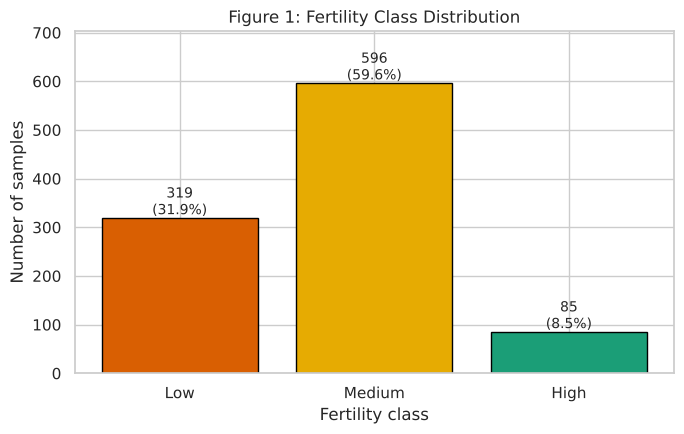

In [14]:
SHORT = {"pH": "pH", "Electrical_Conductivity_dS_m": "EC (dS/m)", "Organic_Carbon_g_kg": "Organic C (g/kg)",
         "Available_N_kg_ha": "N (kg/ha)", "Available_P_kg_ha": "P (kg/ha)", "Available_K_kg_ha": "K (kg/ha)",
         "Sulphur_mg_kg": "Sulphur (mg/kg)", "Zinc_mg_kg": "Zinc (mg/kg)", "Boron_mg_kg": "Boron (mg/kg)",
         "Iron_mg_kg": "Iron (mg/kg)", "Manganese_mg_kg": "Manganese (mg/kg)", "Copper_mg_kg": "Copper (mg/kg)"}

# Figure 1 – Fertility class distribution
fig, ax = plt.subplots(figsize=(7, 4.5))
bars = ax.bar(SHORT_CLASS, class_counts.values, color=[PALETTE[c] for c in CLASS_ORDER], edgecolor="black")
for b, n in zip(bars, class_counts.values):
    ax.text(b.get_x() + b.get_width() / 2, n + 8, f"{n}\n({100 * n / len(df_clean):.1f}%)", ha="center", fontsize=10)
ax.set_ylim(0, class_counts.max() * 1.18)
ax.set_title("Figure 1: Fertility Class Distribution"); ax.set_xlabel("Fertility class"); ax.set_ylabel("Number of samples")
save_show("fig01_class_distribution")

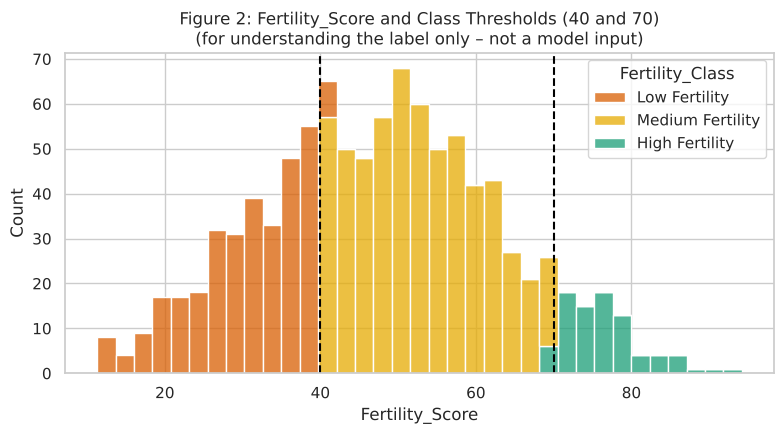

In [15]:
# Figure 2 – The derived Fertility_Score and the README class thresholds (descriptive only; NOT used as a feature)
fig, ax = plt.subplots(figsize=(8, 4.5))
sns.histplot(data=df_clean, x="Fertility_Score", hue="Fertility_Class", hue_order=CLASS_ORDER, palette=PALETTE,
             bins=35, multiple="stack", ax=ax)
for t in (40, 70):
    ax.axvline(t, color="black", linestyle="--")
ax.set_title("Figure 2: Fertility_Score and Class Thresholds (40 and 70)\n(for understanding the label only – not a model input)")
ax.set_xlabel("Fertility_Score")
save_show("fig02_score_distribution")

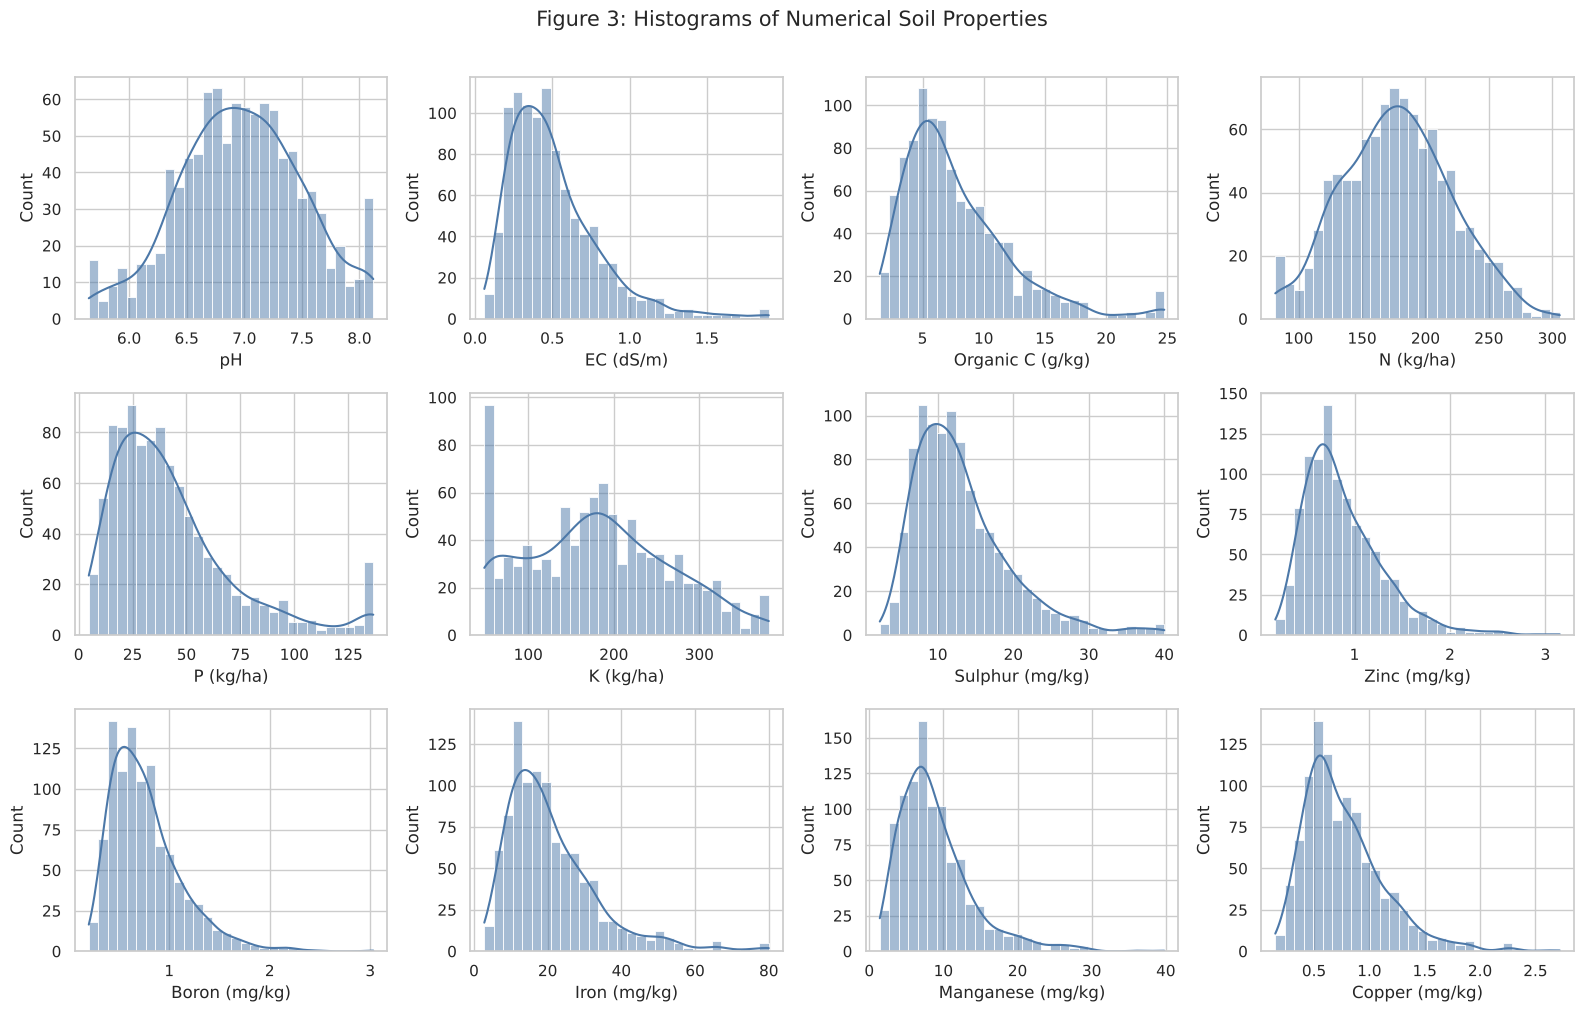

In [16]:
# Figure 3 – Histograms of all 12 numeric soil properties
fig, axes = plt.subplots(3, 4, figsize=(16, 10))
for ax, c in zip(axes.ravel(), NUM_COLS):
    sns.histplot(df_clean[c], kde=True, bins=30, color="#4c78a8", ax=ax)
    ax.set_xlabel(SHORT[c]); ax.set_ylabel("Count")
fig.suptitle("Figure 3: Histograms of Numerical Soil Properties", fontsize=15, y=1.01)
save_show("fig03_histograms")

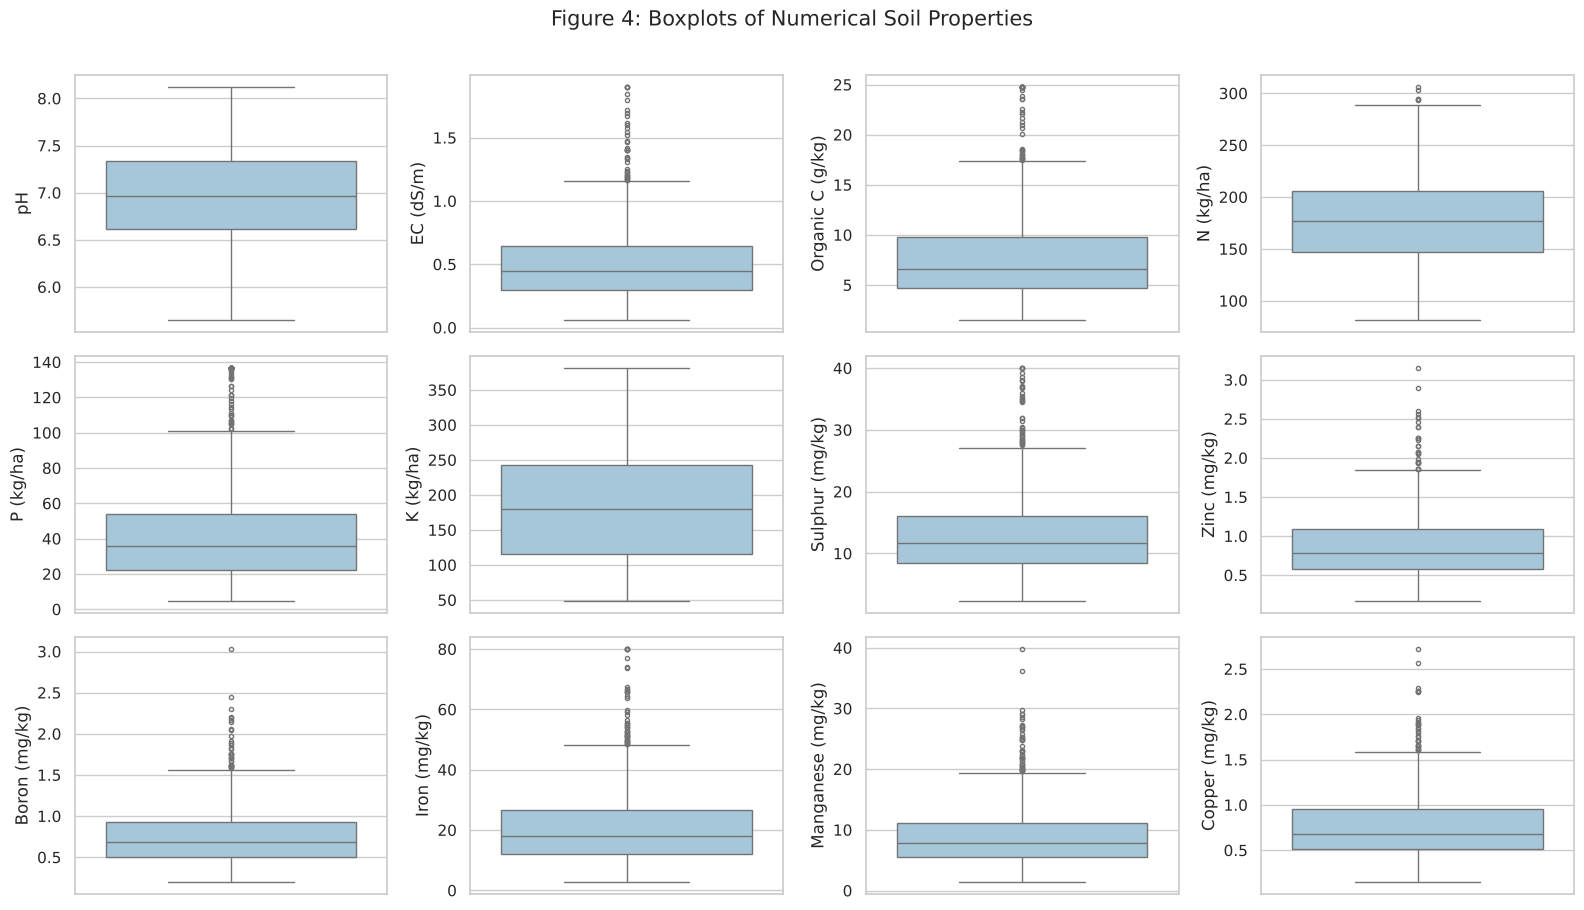

In [17]:
# Figure 4 – Boxplots of all 12 numeric soil properties (outlier view)
fig, axes = plt.subplots(3, 4, figsize=(16, 9))
for ax, c in zip(axes.ravel(), NUM_COLS):
    sns.boxplot(y=df_clean[c], color="#9ecae1", ax=ax, fliersize=3)
    ax.set_ylabel(SHORT[c])
fig.suptitle("Figure 4: Boxplots of Numerical Soil Properties", fontsize=15, y=1.01)
save_show("fig04_boxplots")

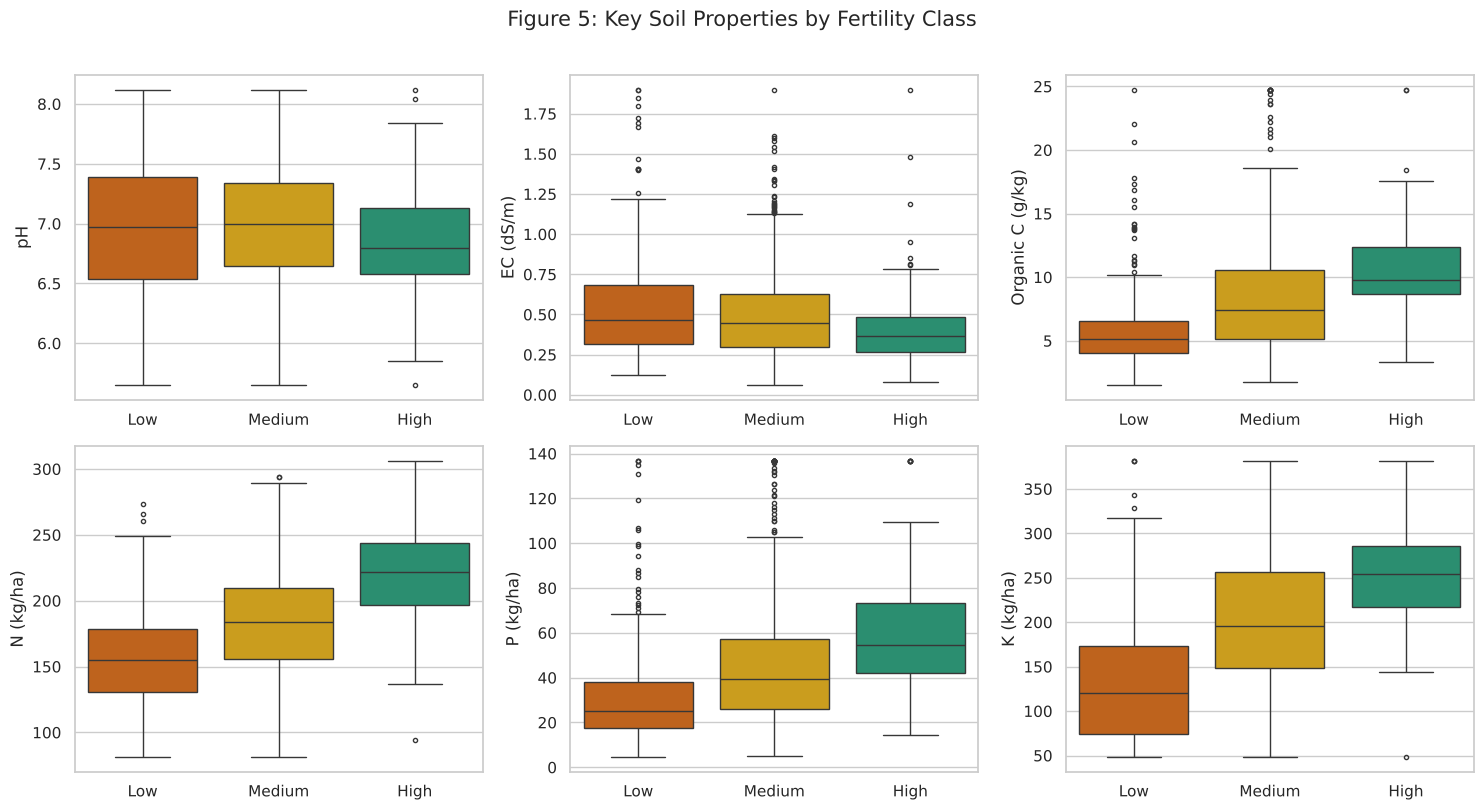

In [18]:
# Figure 5 – Boxplots of the six score-related properties split by fertility class
SIX = ["pH", "Electrical_Conductivity_dS_m", "Organic_Carbon_g_kg", "Available_N_kg_ha", "Available_P_kg_ha", "Available_K_kg_ha"]
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, c in zip(axes.ravel(), SIX):
    sns.boxplot(data=df_clean, x="Fertility_Class", y=c, order=CLASS_ORDER, palette=PALETTE, ax=ax, fliersize=3)
    ax.set_xticklabels(SHORT_CLASS); ax.set_xlabel(""); ax.set_ylabel(SHORT[c])
fig.suptitle("Figure 5: Key Soil Properties by Fertility Class", fontsize=15, y=1.01)
save_show("fig05_boxplots_by_class")

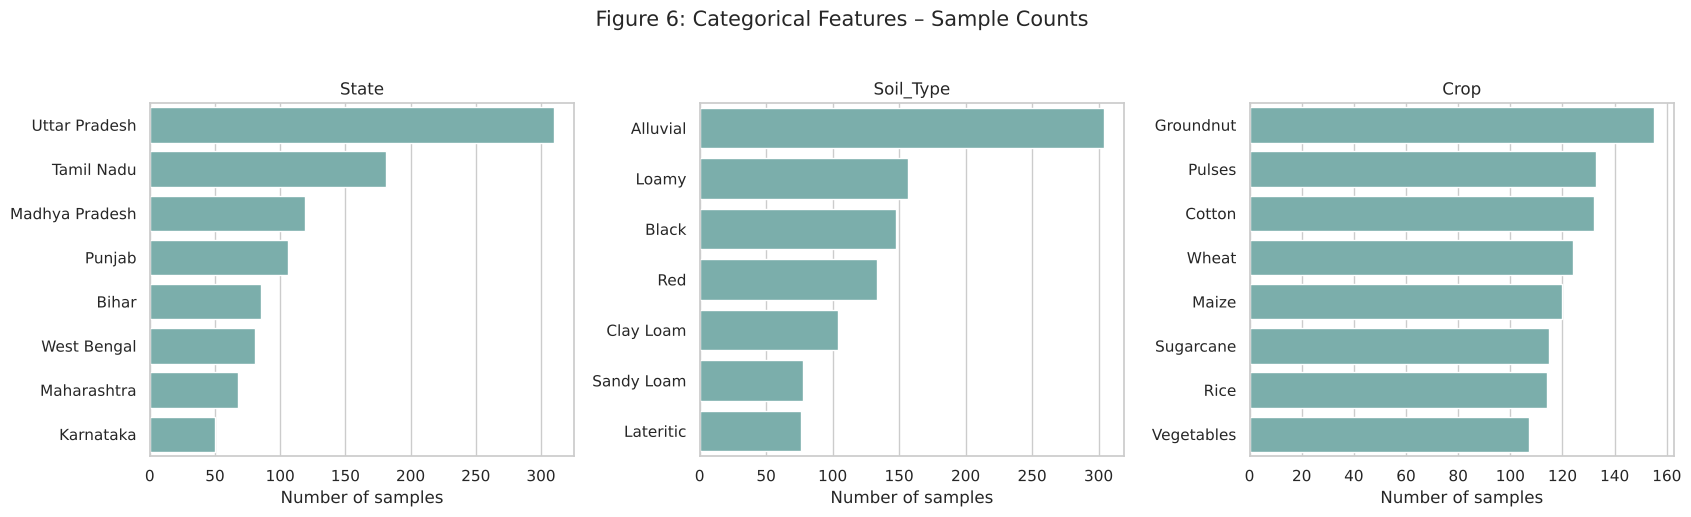

In [19]:
# Figure 6 – Categorical features: number of samples per category
fig, axes = plt.subplots(1, 3, figsize=(17, 5))
for ax, c in zip(axes, ["State", "Soil_Type", "Crop"]):
    order = df_clean[c].value_counts().index
    sns.countplot(data=df_clean, y=c, order=order, color="#72b7b2", ax=ax)
    ax.set_title(c); ax.set_xlabel("Number of samples"); ax.set_ylabel("")
fig.suptitle("Figure 6: Categorical Features – Sample Counts", fontsize=15, y=1.03)
save_show("fig06_categorical_counts")

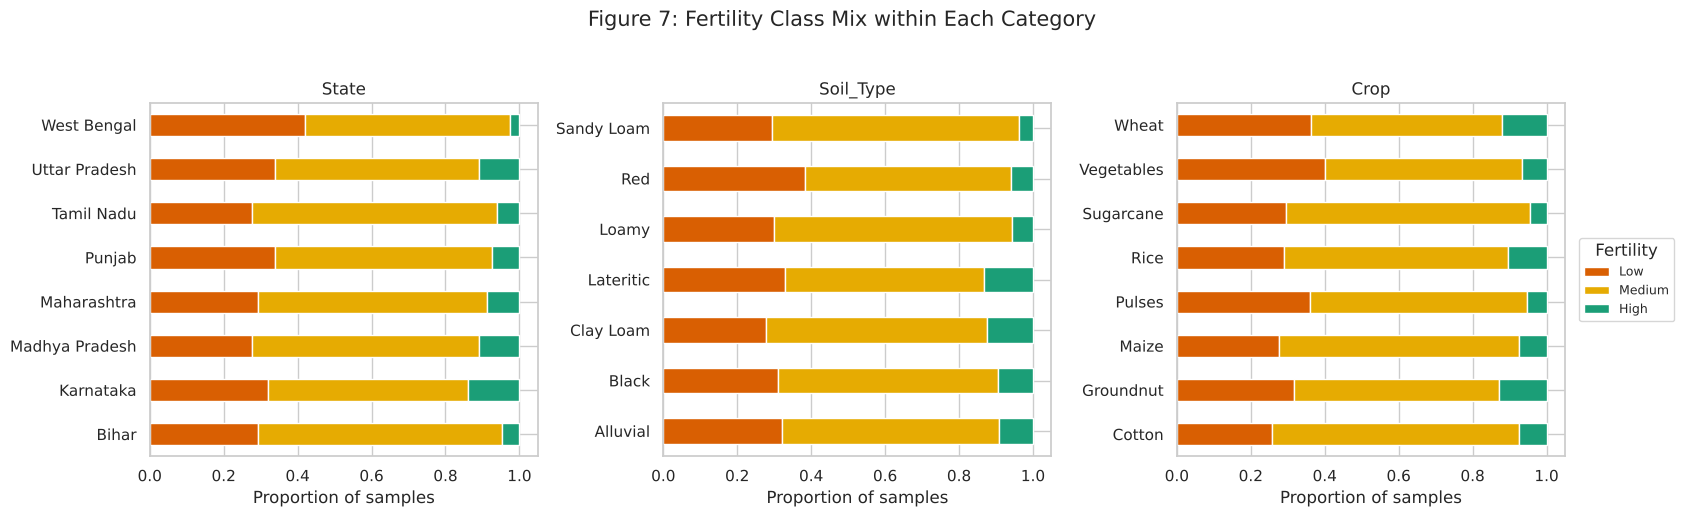

In [20]:
# Figure 7 – Fertility class mix inside each category (100% stacked bars)
fig, axes = plt.subplots(1, 3, figsize=(17, 5))
for ax, c in zip(axes, ["State", "Soil_Type", "Crop"]):
    prop = pd.crosstab(df_clean[c], df_clean["Fertility_Class"], normalize="index")[CLASS_ORDER]
    prop.plot(kind="barh", stacked=True, color=[PALETTE[k] for k in CLASS_ORDER], ax=ax, legend=False, edgecolor="white")
    ax.set_title(c); ax.set_xlabel("Proportion of samples"); ax.set_ylabel("")
axes[-1].legend(SHORT_CLASS, title="Fertility", loc="center left", bbox_to_anchor=(1.02, 0.5), fontsize=9)
fig.suptitle("Figure 7: Fertility Class Mix within Each Category", fontsize=15, y=1.03)
save_show("fig07_class_by_category")

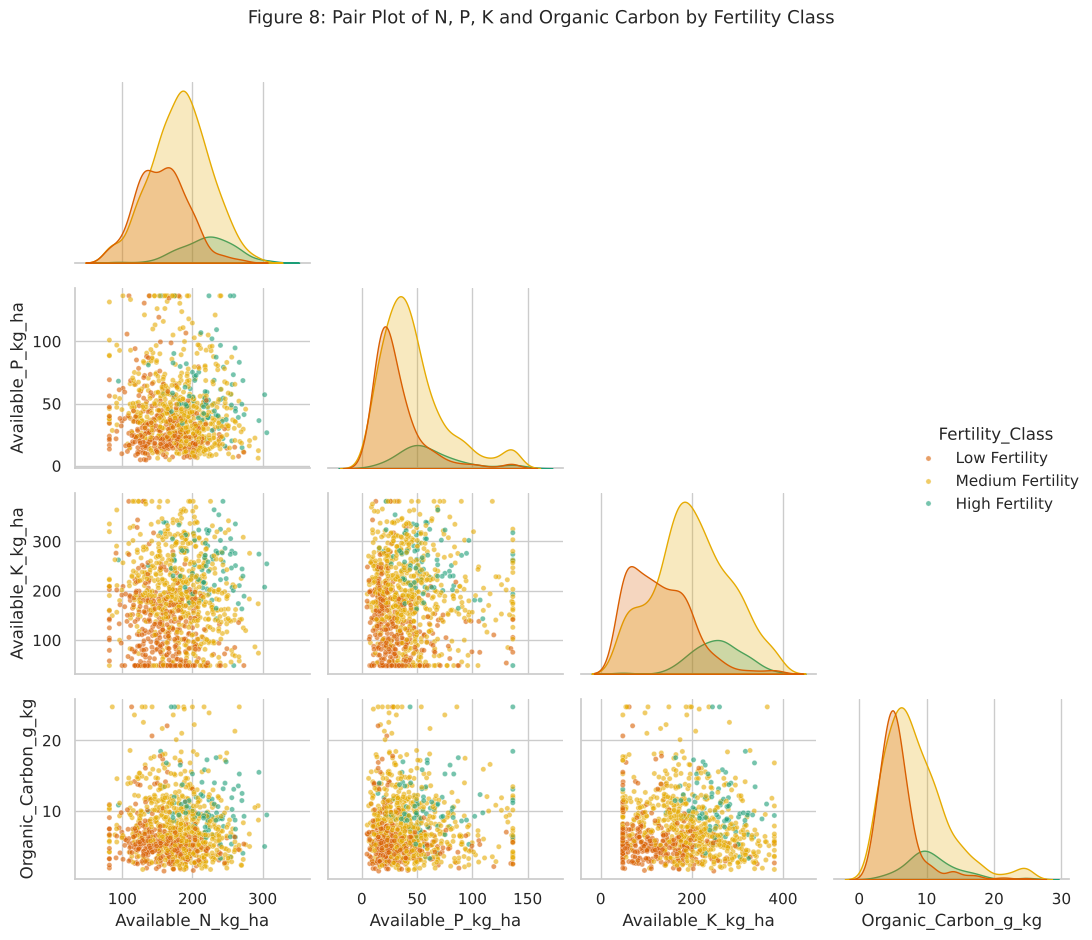

In [21]:
# Figure 8 – Pair plot of the main nutrients (N, P, K, Organic Carbon)
pp = sns.pairplot(df_clean, vars=["Available_N_kg_ha", "Available_P_kg_ha", "Available_K_kg_ha", "Organic_Carbon_g_kg"],
                  hue="Fertility_Class", hue_order=CLASS_ORDER, palette=PALETTE, corner=True,
                  plot_kws={"s": 14, "alpha": 0.6}, diag_kind="kde", height=2.3)
pp.fig.suptitle("Figure 8: Pair Plot of N, P, K and Organic Carbon by Fertility Class", y=1.02, fontsize=13)
save_show("fig08_pairplot", fig=pp.fig)

**How to read the graphs**
* **Fig. 1–2:** *Medium* is the biggest class; the score is split by two vertical cut-offs at 40 and 70.
* **Fig. 3–4:** most nutrients are right-skewed with some high outliers (natural in soil data).
* **Fig. 5:** N, P, K and Organic Carbon clearly shift upward from Low to High; EC is higher in Low-fertility soil; pH overlaps strongly between classes.
* **Fig. 6–7:** the categorical features have fairly even class mixes, so they are not strong predictors.
* **Fig. 8:** classes overlap in every pair of two nutrients – no single pair separates them perfectly, so a model must combine several features.

# TASK 6 – Correlation Analysis
**What we do:** measure the linear relationship (Pearson *r*, from −1 to +1) between every pair of numeric soil properties and draw a heatmap.
`Fertility_Score` is excluded because it is a derived target-related field.

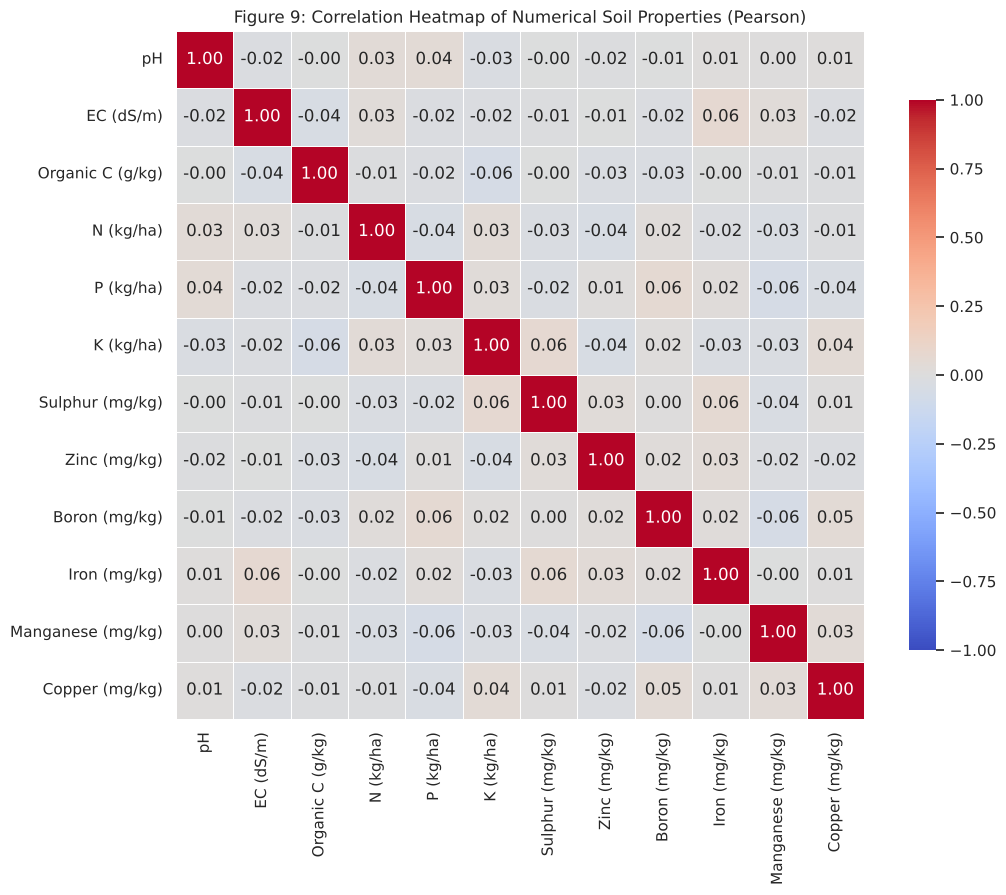

,Feature 1,Feature 2,r,|r|
21,Electrical_Conductivity_dS_m,Iron_mg_kg,0.065,0.065
66,Available_K_kg_ha,Sulphur_mg_kg,0.063,0.063
56,Available_P_kg_ha,Boron_mg_kg,0.060,0.060
58,Available_P_kg_ha,Manganese_mg_kg,-0.059,0.059
81,Sulphur_mg_kg,Iron_mg_kg,0.058,0.058


Largest absolute correlation between two features = 0.065


In [22]:
corr = df_clean[NUM_COLS].corr(method="pearson")
corr_pretty = corr.rename(index=SHORT, columns=SHORT)
fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(corr_pretty, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, linewidths=0.5, square=True, ax=ax,
            cbar_kws={"shrink": 0.8})
ax.set_title("Figure 9: Correlation Heatmap of Numerical Soil Properties (Pearson)")
save_show("fig09_correlation_heatmap")
save_table(corr.round(3), "06_correlation_matrix")

# strongest pairs
pairs = (corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack().rename("r").reset_index())
pairs.columns = ["Feature 1", "Feature 2", "r"]
pairs["|r|"] = pairs["r"].abs()
top_pairs = pairs.sort_values("|r|", ascending=False).head(5).round(3)
display(top_pairs)
save_table(top_pairs, "06_top_correlated_pairs", index=False)
print(f"Largest absolute correlation between two features = {pairs['|r|'].max():.3f}")

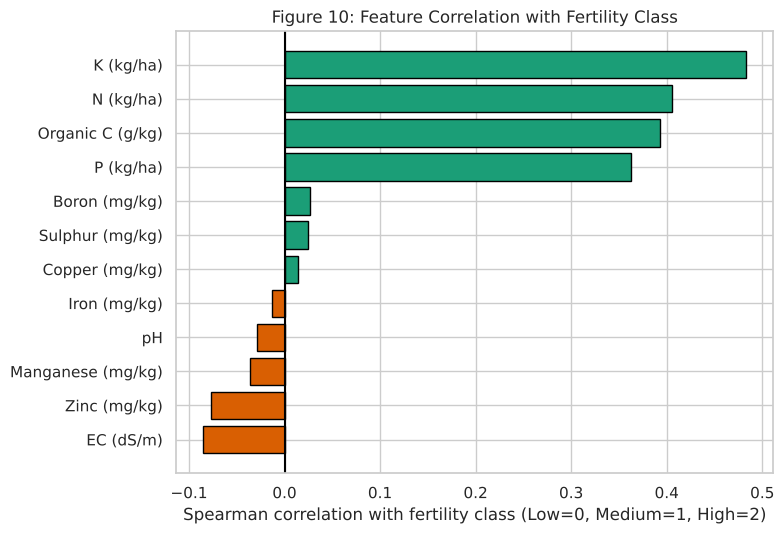

,Electrical_Conductivity_dS_m,Zinc_mg_kg,Manganese_mg_kg,pH,Iron_mg_kg,Copper_mg_kg,Sulphur_mg_kg,Boron_mg_kg,Available_P_kg_ha,Organic_Carbon_g_kg,Available_N_kg_ha,Available_K_kg_ha
Spearman with class,-0.085,-0.077,-0.036,-0.029,-0.014,0.015,0.025,0.027,0.363,0.393,0.405,0.483


In [23]:
# Figure 10 – How strongly is each feature related to the fertility class? (Spearman rank correlation with the ordered class 0/1/2)
y_ordinal = df_clean["Fertility_Class"].map(CLASS_MAP)
target_corr = df_clean[NUM_COLS].apply(lambda s: s.corr(y_ordinal, method="spearman")).sort_values()
fig, ax = plt.subplots(figsize=(8, 5.5))
ax.barh([SHORT[c] for c in target_corr.index], target_corr.values,
        color=["#d95f02" if v < 0 else "#1b9e77" for v in target_corr.values], edgecolor="black")
ax.axvline(0, color="black"); ax.set_xlabel("Spearman correlation with fertility class (Low=0, Medium=1, High=2)")
ax.set_title("Figure 10: Feature Correlation with Fertility Class")
save_show("fig10_target_correlation")
save_table(target_corr.rename("Spearman_with_class").round(3).to_frame(), "06_target_correlation")
display(target_corr.round(3).to_frame("Spearman with class").T)

In [24]:
# Evidence for a U-shaped pH effect: average ordinal fertility class (0=Low, 1=Medium, 2=High) inside pH bands
ph_bins = pd.cut(df_clean["pH"], bins=[5, 6, 6.5, 6.8, 7.2, 7.5, 8, 9])
ph_effect = df_clean.groupby(ph_bins, observed=True).apply(
    lambda g: pd.Series({"Samples": len(g), "Mean fertility class (0-2)": y_ordinal.loc[g.index].mean(),
                         "% Low": 100 * (g["Fertility_Class"] == "Low Fertility").mean(),
                         "% High": 100 * (g["Fertility_Class"] == "High Fertility").mean()})).round(2)
ph_effect.index = ph_effect.index.astype(str)
display(ph_effect)
save_table(ph_effect, "06_ph_effect")

,Samples,Mean fertility class (0-2),% Low,% High
pH,,,,
"(5.0, 6.0]",47.0,0.57,46.81,4.26
"(6.0, 6.5]",148.0,0.74,34.46,8.78
"(6.5, 6.8]",194.0,0.88,26.80,14.43
"(6.8, 7.2]",274.0,0.80,29.56,9.12
"(7.2, 7.5]",167.0,0.74,31.14,5.39
"(7.5, 8.0]",132.0,0.70,34.85,4.55
"(8.0, 9.0]",38.0,0.66,39.47,5.26


**Findings**
* The soil properties are almost **uncorrelated with each other** (all pairwise |r| are tiny). This is typical of synthetic data generated independently, and it means there is **no multicollinearity problem**.
* N, P, K and Organic Carbon have a clear **positive** relationship with the class; EC has a **negative** one (more salt → lower fertility).
* pH has almost no *linear/rank* correlation with the class. In the score, pH is best near the neutral range, so both very low and very high pH hurt – a "U-shaped" effect that a straight-line correlation cannot capture. Tree-based and kernel models can learn such patterns.

# TASK 7 – Feature Selection
**Goal:** choose input features that are (1) relevant, (2) available when a farmer tests a new soil sample, and (3) free from **target leakage**.

**Step A – Remove columns that must not be inputs**
| Column | Decision | Reason |
|---|---|---|
| `Fertility_Score` | ❌ Exclude | The class was *calculated* from it → direct **target leakage** |
| `Fertility_Class` | ❌ Target | This is what we predict |
| `Sample_ID` | ❌ Exclude | Just an identifier, no soil information |
| `Source_Calibration` | ❌ Exclude | Describes how the synthetic data was made, not a soil property |
| `District` | ❌ Exclude | Highly detailed (18 values) and repeats the information in `State` |

**Step B – Statistical evidence** (mutual information for numeric features, Cramér's V for categorical features from Task 4).
**Step C – Domain knowledge from the README:** the label is derived from **N, P, K, Organic Carbon, pH and EC**.
These are ordinary soil-test measurements, so using them is *not* leakage – the score itself is the leaked item, and it is excluded.

> *Note:* the statistics in Step B use the full dataset for guidance only. The choice is confirmed again, using **training data only**, in Task 9.

In [25]:
mi = mutual_info_classif(df_clean[NUM_COLS], y_ordinal, random_state=RANDOM_STATE)
SCORE_COMPONENTS = SIX
sel_table = pd.DataFrame({
    "Feature": NUM_COLS,
    "Mutual information": mi.round(3),
    "Spearman with class": [round(df_clean[c].corr(y_ordinal, method="spearman"), 3) for c in NUM_COLS],
    "In README score formula?": ["Yes" if c in SCORE_COMPONENTS else "No" for c in NUM_COLS],
})
sel_table["Decision"] = np.where(sel_table["In README score formula?"] == "Yes", "SELECT", "Drop")
sel_table = sel_table.sort_values("Mutual information", ascending=False).reset_index(drop=True)
display(sel_table)
save_table(sel_table, "07_feature_selection", index=False)

,Feature,Mutual information,Spearman with class,In README score formula?,Decision
0,Available_K_kg_ha,0.137,0.483,Yes,SELECT
1,Available_N_kg_ha,0.121,0.405,Yes,SELECT
2,Organic_Carbon_g_kg,0.094,0.393,Yes,SELECT
3,Available_P_kg_ha,0.055,0.363,Yes,SELECT
4,Zinc_mg_kg,0.024,-0.077,No,Drop
5,Boron_mg_kg,0.012,0.027,No,Drop
6,Sulphur_mg_kg,0.007,0.025,No,Drop
7,Electrical_Conductivity_dS_m,0.002,-0.085,Yes,SELECT
8,pH,0.000,-0.029,Yes,SELECT
9,Iron_mg_kg,0.000,-0.014,No,Drop


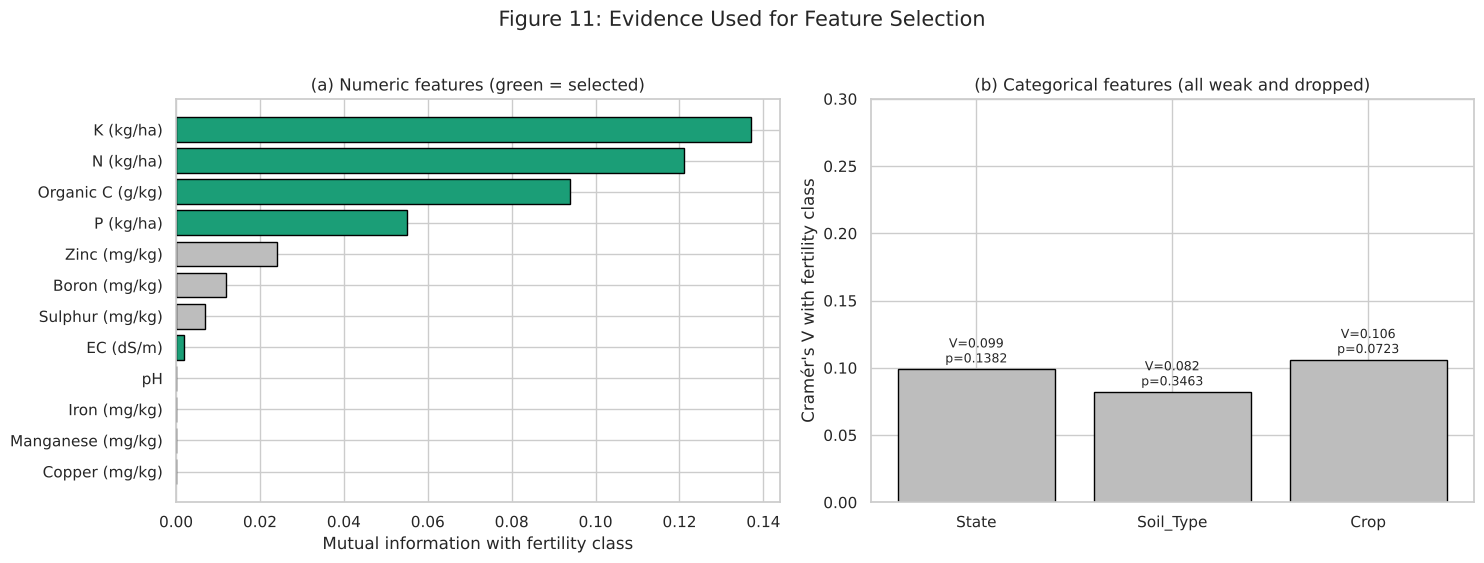

In [26]:
# Figure 11 – evidence used for feature selection
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
order = sel_table.sort_values("Mutual information")
axes[0].barh([SHORT[c] for c in order["Feature"]], order["Mutual information"],
             color=["#1b9e77" if d == "SELECT" else "#bdbdbd" for d in order["Decision"]], edgecolor="black")
axes[0].set_xlabel("Mutual information with fertility class"); axes[0].set_title("(a) Numeric features (green = selected)")
cv_ = chi_table[chi_table["Categorical feature"].isin(["State", "Soil_Type", "Crop"])]
axes[1].bar(cv_["Categorical feature"], cv_["Cramér's V"], color="#bdbdbd", edgecolor="black")
axes[1].set_ylim(0, 0.3); axes[1].set_ylabel("Cramér's V with fertility class")
axes[1].set_title("(b) Categorical features (all weak and dropped)")
for i, (v, p) in enumerate(zip(cv_["Cramér's V"], cv_["p-value"])):
    axes[1].text(i, v + 0.005, f"V={v}\np={p}", ha="center", fontsize=9)
fig.suptitle("Figure 11: Evidence Used for Feature Selection", fontsize=15, y=1.02)
save_show("fig11_feature_selection")

**Interpretation**
* **N, K, Organic Carbon and P** have the highest mutual information with the class.
* **pH and EC** show low *univariate* mutual information. This does not mean they are useless: a single-feature filter cannot see an effect that only appears *together with* other features or that is U-shaped. The README states that they are part of the score, and Task 9 re-checks this with cross-validation.
* **Sulphur and the five micronutrients** have near-zero information about the class and are not in the score formula → dropped.
* **State, Soil_Type and Crop** are statistically weak (small Cramér's V) → dropped.

### Final selected features (6)
`pH`, `Electrical_Conductivity_dS_m`, `Organic_Carbon_g_kg`, `Available_N_kg_ha`, `Available_P_kg_ha`, `Available_K_kg_ha`

In [27]:
FEATURES = SCORE_COMPONENTS.copy()
TARGET = "Fertility_Class"
print("Selected features:", FEATURES)
print("Leakage check – Fertility_Score in features?", "Fertility_Score" in FEATURES)
assert "Fertility_Score" not in FEATURES and TARGET not in FEATURES

Selected features: ['pH', 'Electrical_Conductivity_dS_m', 'Organic_Carbon_g_kg', 'Available_N_kg_ha', 'Available_P_kg_ha', 'Available_K_kg_ha']
Leakage check – Fertility_Score in features? False


# TASK 8 – Train-Test Split
**What we do:** split the data into **80 % training** and **20 % testing** data.
* `stratify=y` keeps the same Low/Medium/High proportions in both parts (important because *High* is rare).
* `random_state=42` makes the split identical every time.
* The test set is kept untouched until the final evaluation, so the scores reflect performance on *unseen* soils.

Training set: (800, 6) | Test set: (200, 6)


,Full data,Train,Test,Full data %,Train %,Test %
Low Fertility,319,255,64,31.9,31.9,32.0
Medium Fertility,596,477,119,59.6,59.6,59.5
High Fertility,85,68,17,8.5,8.5,8.5


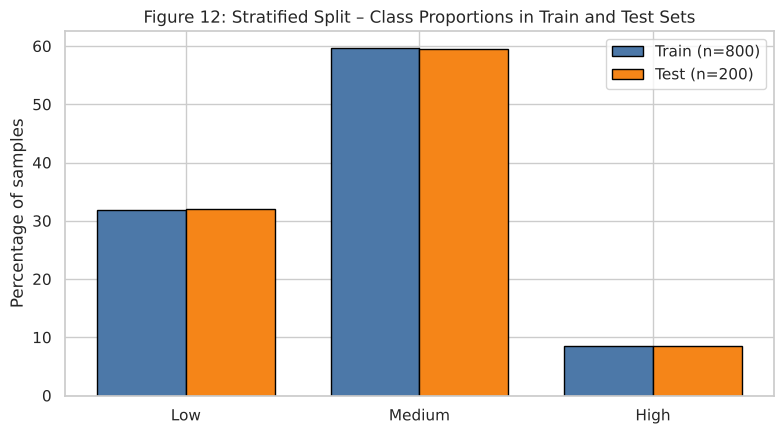

In [28]:
X = df_clean[FEATURES].copy()
y = df_clean[TARGET].map(CLASS_MAP)             # target encoding: Low=0, Medium=1, High=2

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE)

print("Training set:", X_train.shape, "| Test set:", X_test.shape)
split_table = pd.DataFrame({
    "Full data": y.value_counts().sort_index(),
    "Train": y_train.value_counts().sort_index(),
    "Test": y_test.value_counts().sort_index(),
})
split_table.index = CLASS_ORDER
for col in ["Full data", "Train", "Test"]:
    split_table[col + " %"] = (100 * split_table[col] / split_table[col].sum()).round(1)
display(split_table)
save_table(split_table, "08_split_distribution")

# Figure 12 – class proportions in train and test
fig, ax = plt.subplots(figsize=(8, 4.5))
x = np.arange(3); w = 0.38
ax.bar(x - w / 2, split_table["Train %"], w, label=f"Train (n={len(y_train)})", color="#4c78a8", edgecolor="black")
ax.bar(x + w / 2, split_table["Test %"], w, label=f"Test (n={len(y_test)})", color="#f58518", edgecolor="black")
ax.set_xticks(x); ax.set_xticklabels(SHORT_CLASS); ax.set_ylabel("Percentage of samples"); ax.legend()
ax.set_title("Figure 12: Stratified Split – Class Proportions in Train and Test Sets")
save_show("fig12_split_distribution")

# TASK 9 – Implement and Compare Four Classification Algorithms
### Preprocessing and encoding
* **Target encoding:** Low = 0, Medium = 1, High = 2 (done in Task 8).
* **Missing values:** `SimpleImputer(median)` inside the pipeline (nothing is missing now, but it protects new inputs).
* **Feature scaling:** `StandardScaler` for **KNN and SVM**, because they depend on distances between samples and a feature like K (0–400) would otherwise dominate pH (5–8).
  **Decision Tree and Random Forest** split on thresholds and are not affected by scale, so no scaling is applied to them.
* **Categorical encoding:** the selected features are all numeric. For completeness, the helper below can one-hot encode categorical columns; it is used in the feature-set check further down.
* **Pipelines:** every step lives inside a scikit-learn `Pipeline`, so the imputer/scaler learn only from training data (no leakage) and new samples are processed in exactly the same way.

### The four algorithms (simple settings, no heavy tuning)
| Algorithm | Idea in one line | Settings |
|---|---|---|
| Decision Tree | A flow-chart of yes/no questions on feature values | `max_depth=5` (prevents memorising) |
| Random Forest | Many trees vote together | `n_estimators=200` |
| KNN | Look at the *k* most similar known soils and take a majority vote | `k=7`, scaled features |
| SVM | Finds the best boundary between classes (RBF kernel curves the boundary) | `C=1`, `gamma='scale'`, scaled features |

In [29]:
def build_preprocessor(num_cols, cat_cols=(), scale=False):
    """Imputation + (optional) scaling for numeric columns, imputation + one-hot for categorical columns."""
    num_steps = [("imputer", SimpleImputer(strategy="median"))]
    if scale:
        num_steps.append(("scaler", StandardScaler()))
    transformers = [("num", Pipeline(num_steps), list(num_cols))]
    if len(cat_cols) > 0:
        transformers.append(("cat", Pipeline([("imputer", SimpleImputer(strategy="most_frequent")),
                                              ("onehot", OneHotEncoder(handle_unknown="ignore"))]), list(cat_cols)))
    return ColumnTransformer(transformers)

MODEL_SPECS = {
    "Decision Tree": (DecisionTreeClassifier(max_depth=5, random_state=RANDOM_STATE), False),
    "Random Forest": (RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1), False),
    "KNN":           (KNeighborsClassifier(n_neighbors=7), True),
    "SVM":           (SVC(kernel="rbf", C=1.0, gamma="scale", probability=True, random_state=RANDOM_STATE), True),
}

def make_pipeline(name, num_cols=FEATURES, cat_cols=()):
    model, scale = MODEL_SPECS[name]
    from sklearn.base import clone
    return Pipeline([("prep", build_preprocessor(num_cols, cat_cols, scale)), ("model", clone(model))])

pipelines = {name: make_pipeline(name) for name in MODEL_SPECS}
for name, pipe in pipelines.items():
    pipe.fit(X_train, y_train)               # fitted on TRAINING data only
    print(f"{name:14s} trained.")

Decision Tree  trained.


Random Forest  trained.
KNN            trained.
SVM            trained.


### 9.1 Cross-validation on the training set (5-fold, stratified)
Cross-validation repeatedly trains on 4/5 of the training data and validates on the remaining 1/5. It shows how *stable* each model is
**without touching the test set**, so we can later use it to pick the final model fairly.

In [30]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_rows = []
for name, pipe in pipelines.items():
    res = cross_validate(make_pipeline(name), X_train, y_train, cv=skf,
                         scoring=["accuracy", "f1_macro", "f1_weighted"], n_jobs=1)
    cv_rows.append((name, res["test_accuracy"].mean(), res["test_accuracy"].std(),
                    res["test_f1_macro"].mean(), res["test_f1_macro"].std(), res["test_f1_weighted"].mean()))
cv_table = pd.DataFrame(cv_rows, columns=["Model", "CV Accuracy (mean)", "CV Accuracy (std)",
                                          "CV Macro F1 (mean)", "CV Macro F1 (std)", "CV Weighted F1 (mean)"]).set_index("Model").round(4)
display(cv_table)
save_table(cv_table, "09_cross_validation")

,CV Accuracy (mean),CV Accuracy (std),CV Macro F1 (mean),CV Macro F1 (std),CV Weighted F1 (mean)
Model,,,,,
Decision Tree,0.7912,0.0196,0.6913,0.0528,0.7816
Random Forest,0.8838,0.0242,0.8257,0.0259,0.8786
KNN,0.8075,0.0199,0.7486,0.0274,0.8020
SVM,0.8662,0.0252,0.8230,0.0459,0.8636


### 9.2 Re-checking feature selection with training data only
We compare three feature sets using 5-fold CV on the **training** data (macro F1):
* **A** – the 6 selected features (N, P, K, OC, pH, EC)
* **B** – all 12 numeric soil properties
* **C** – all 12 numeric + State, Soil_Type, Crop (categorical, one-hot encoded)

If A is as good as or better than B and C, the extra columns only add noise.

In [31]:
CAT_FOR_CHECK = ["State", "Soil_Type", "Crop"]
sets = {"A: 6 selected": (FEATURES, []), "B: all 12 numeric": (NUM_COLS, []), "C: 12 numeric + 3 categorical": (NUM_COLS, CAT_FOR_CHECK)}
fs_rows = []
for set_name, (nc, cc) in sets.items():
    Xtr = df_clean.loc[X_train.index, nc + cc]
    row = {"Feature set": set_name, "No. of input columns": len(nc) + len(cc)}
    for name in MODEL_SPECS:
        s = cross_validate(make_pipeline(name, nc, cc), Xtr, y_train, cv=skf, scoring="f1_macro")["test_score"].mean()
        row[name] = round(s, 4)
    fs_rows.append(row)
fs_table = pd.DataFrame(fs_rows).set_index("Feature set")
display(fs_table)
save_table(fs_table, "09_feature_set_check")
print("Mean macro-F1 across the four models:\n", fs_table[list(MODEL_SPECS)].mean(axis=1).round(4).to_string())

,No. of input columns,Decision Tree,Random Forest,KNN,SVM
Feature set,,,,,
A: 6 selected,6,0.6913,0.8257,0.7486,0.8230
B: all 12 numeric,12,0.6911,0.7366,0.6021,0.7083
C: 12 numeric + 3 categorical,15,0.6832,0.5762,0.5826,0.6968


Mean macro-F1 across the four models:
 Feature set
A: 6 selected                    0.7722
B: all 12 numeric                0.6845
C: 12 numeric + 3 categorical    0.6347


# TASK 10 – Model Evaluation Metrics
All four trained pipelines now predict the **unseen test set** (20 % of the data).
* **Accuracy** – share of all predictions that are correct.
* **Precision** – of the soils predicted as a class, how many truly belong to it.
* **Recall** – of the soils that truly belong to a class, how many were found.
* **F1-score** – the balance (harmonic mean) of precision and recall.
* **Macro average** – simple average over the 3 classes (treats the rare *High* class equally).
* **Weighted average** – average weighted by how many test samples each class has.

In [32]:
predictions = {name: pipe.predict(X_test) for name, pipe in pipelines.items()}

metric_rows = []
for name, pred in predictions.items():
    metric_rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision (macro)": precision_score(y_test, pred, average="macro", zero_division=0),
        "Recall (macro)": recall_score(y_test, pred, average="macro", zero_division=0),
        "F1 (macro)": f1_score(y_test, pred, average="macro", zero_division=0),
        "Precision (weighted)": precision_score(y_test, pred, average="weighted", zero_division=0),
        "Recall (weighted)": recall_score(y_test, pred, average="weighted", zero_division=0),
        "F1 (weighted)": f1_score(y_test, pred, average="weighted", zero_division=0),
    })
metrics = pd.DataFrame(metric_rows).set_index("Model").round(4)
display(metrics)
save_table(metrics, "10_test_metrics")

,Accuracy,Precision (macro),Recall (macro),F1 (macro),Precision (weighted),Recall (weighted),F1 (weighted)
Model,,,,,,,
Decision Tree,0.820,0.8304,0.6854,0.7224,0.8218,0.820,0.8111
Random Forest,0.900,0.8898,0.8239,0.8518,0.9000,0.900,0.8980
KNN,0.840,0.8532,0.7326,0.7711,0.8419,0.840,0.8349
SVM,0.915,0.9326,0.9043,0.9171,0.9167,0.915,0.9154


In [33]:
# Per-class precision / recall / F1 for each model
per_class_frames = []
for name, pred in predictions.items():
    rep = classification_report(y_test, pred, target_names=CLASS_ORDER, output_dict=True, zero_division=0)
    df_rep = pd.DataFrame(rep).T.loc[CLASS_ORDER + ["macro avg", "weighted avg"], ["precision", "recall", "f1-score", "support"]]
    df_rep.insert(0, "Model", name)
    per_class_frames.append(df_rep)
    print(f"\n=== {name} ===")
    print(classification_report(y_test, pred, target_names=CLASS_ORDER, zero_division=0, digits=3))
per_class = pd.concat(per_class_frames).round(4)
save_table(per_class, "10_per_class_report")


=== Decision Tree ===
                  precision    recall  f1-score   support

   Low Fertility      0.812     0.812     0.812        64
Medium Fertility      0.822     0.891     0.855       119
  High Fertility      0.857     0.353     0.500        17

        accuracy                          0.820       200
       macro avg      0.830     0.685     0.722       200
    weighted avg      0.822     0.820     0.811       200


=== Random Forest ===
                  precision    recall  f1-score   support

   Low Fertility      0.933     0.875     0.903        64
Medium Fertility      0.890     0.950     0.919       119
  High Fertility      0.846     0.647     0.733        17

        accuracy                          0.900       200
       macro avg      0.890     0.824     0.852       200
    weighted avg      0.900     0.900     0.898       200


=== KNN ===
                  precision    recall  f1-score   support

   Low Fertility      0.828     0.828     0.828        64
Medium

# TASK 11 – Confusion Matrices
A confusion matrix is a table where **rows = true class** and **columns = predicted class**. Numbers on the diagonal are correct predictions; numbers
off the diagonal are mistakes. The second figure shows the same matrices as row percentages (i.e. recall for each true class).

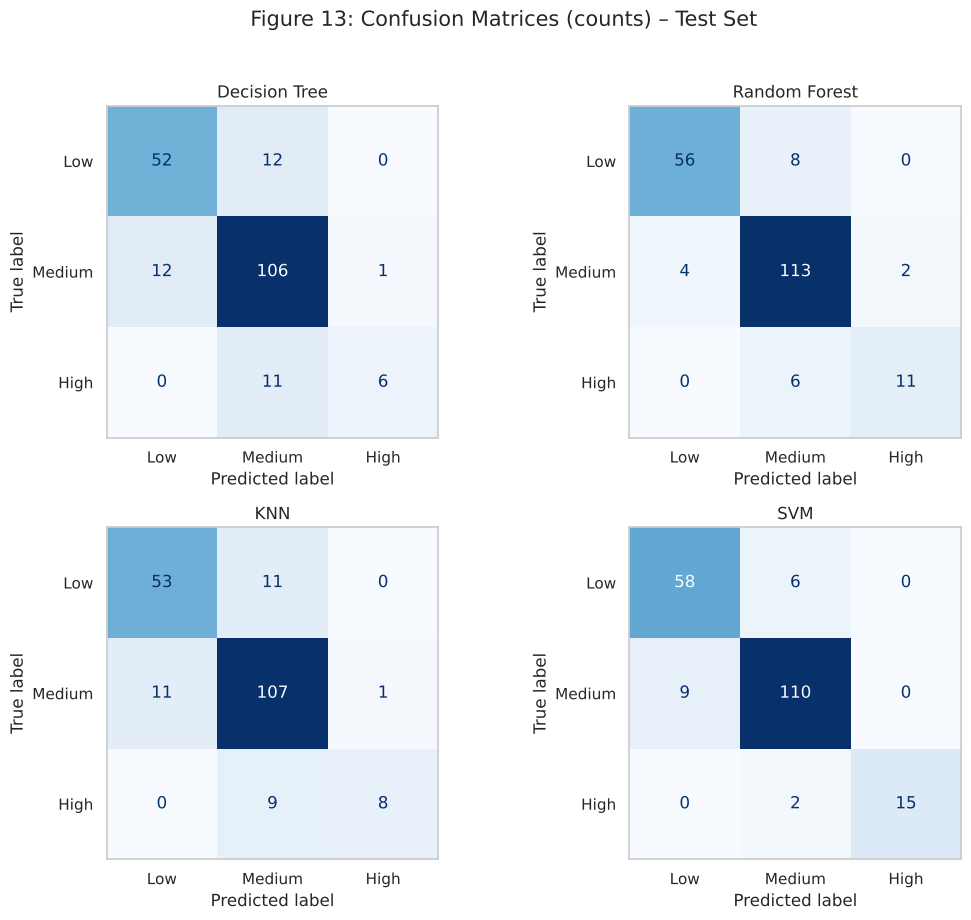

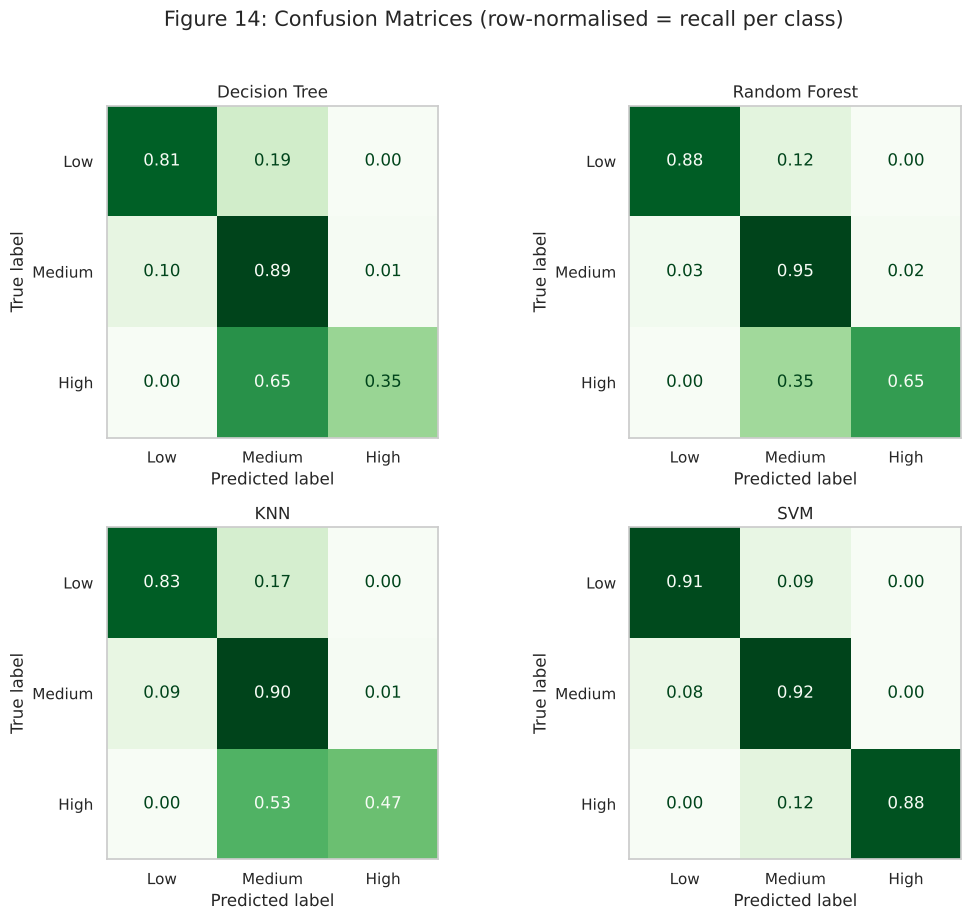

Main error patterns on the test set:
  Decision Tree  total mistakes =  36 of 200  |  true Low → predicted Medium: 12; true Medium → predicted Low: 12; true High → predicted Medium: 11; true Medium → predicted High: 1
  Random Forest  total mistakes =  20 of 200  |  true Low → predicted Medium: 8; true High → predicted Medium: 6; true Medium → predicted Low: 4; true Medium → predicted High: 2
  KNN            total mistakes =  32 of 200  |  true Low → predicted Medium: 11; true Medium → predicted Low: 11; true High → predicted Medium: 9; true Medium → predicted High: 1
  SVM            total mistakes =  17 of 200  |  true Medium → predicted Low: 9; true Low → predicted Medium: 6; true High → predicted Medium: 2


In [34]:
cms = {name: confusion_matrix(y_test, pred, labels=[0, 1, 2]) for name, pred in predictions.items()}

fig, axes = plt.subplots(2, 2, figsize=(11, 9))
for ax, (name, pred) in zip(axes.ravel(), predictions.items()):
    ConfusionMatrixDisplay.from_predictions(y_test, pred, labels=[0, 1, 2], display_labels=SHORT_CLASS, cmap="Blues",
                                            ax=ax, colorbar=False)
    ax.set_title(name); ax.grid(False)
fig.suptitle("Figure 13: Confusion Matrices (counts) – Test Set", fontsize=15, y=1.02)
save_show("fig13_confusion_matrices")

fig, axes = plt.subplots(2, 2, figsize=(11, 9))
for ax, (name, pred) in zip(axes.ravel(), predictions.items()):
    ConfusionMatrixDisplay.from_predictions(y_test, pred, labels=[0, 1, 2], display_labels=SHORT_CLASS, cmap="Greens",
                                            normalize="true", values_format=".2f", ax=ax, colorbar=False)
    ax.set_title(name); ax.grid(False)
fig.suptitle("Figure 14: Confusion Matrices (row-normalised = recall per class)", fontsize=15, y=1.02)
save_show("fig14_confusion_matrices_normalized")

# Save as table + describe the mistakes in words
cm_rows = []
for name, cm in cms.items():
    for i, t in enumerate(SHORT_CLASS):
        for j, p in enumerate(SHORT_CLASS):
            cm_rows.append((name, t, p, int(cm[i, j])))
save_table(pd.DataFrame(cm_rows, columns=["Model", "True class", "Predicted class", "Count"]), "11_confusion_matrices", index=False)

print("Main error patterns on the test set:")
for name, cm in cms.items():
    errors = [(SHORT_CLASS[i], SHORT_CLASS[j], int(cm[i, j])) for i in range(3) for j in range(3) if i != j and cm[i, j] > 0]
    errors.sort(key=lambda t: -t[2])
    wrong = sum(e[2] for e in errors)
    txt = "; ".join(f"true {a} → predicted {b}: {n}" for a, b, n in errors) or "no errors"
    print(f"  {name:14s} total mistakes = {wrong:3d} of {cm.sum()}  |  {txt}")

**Explanation of the matrices (test set = 200 soils: 64 Low, 119 Medium, 17 High)**
* **SVM** makes the fewest mistakes (17 of 200), **Random Forest** 20, **KNN** 32 and **Decision Tree** 36.
* Every model's mistakes are between **neighbouring classes** (Low↔Medium or Medium↔High) – a soil close to a cut-off score (40 or 70) can easily fall on the wrong side.
  **No model ever confuses Low with High**, which would be the most serious kind of error.
* The weak spot of every model is the rare **High** class. Its recall (the share of truly High soils that are found) is
  0.35 for Decision Tree, 0.47 for KNN, 0.65 for Random Forest and 0.88 for SVM (15 of 17). Most missed High soils are predicted as Medium.
* Because the High class has only 17 test samples, one extra mistake changes its recall by about 6 percentage points – so these class-level numbers should be read with care.

# TASK 12 – Model Comparison
We put all results in one table and chart. **Selection rule:** the final model is the one with the best **macro-F1 on the unseen test set**
(macro-F1 treats the rare *High* class equally to the large *Medium* class, so it is stricter than accuracy).
We then check that the choice is supported by (a) the cross-validated scores from the training data and (b) a small gap between training and test accuracy
(a large gap means the model has memorised the training data – *overfitting*).

,Accuracy,Precision (macro),Recall (macro),F1 (macro),Precision (weighted),Recall (weighted),F1 (weighted),CV Accuracy (mean),CV Macro F1 (mean),CV Macro F1 (std),Rank (test macro-F1),Rank (CV macro-F1)
Model,,,,,,,,,,,,
Decision Tree,0.820,0.8304,0.6854,0.7224,0.8218,0.820,0.8111,0.7912,0.6913,0.0528,4,4
Random Forest,0.900,0.8898,0.8239,0.8518,0.9000,0.900,0.8980,0.8838,0.8257,0.0259,2,1
KNN,0.840,0.8532,0.7326,0.7711,0.8419,0.840,0.8349,0.8075,0.7486,0.0274,3,3
SVM,0.915,0.9326,0.9043,0.9171,0.9167,0.915,0.9154,0.8662,0.8230,0.0459,1,2


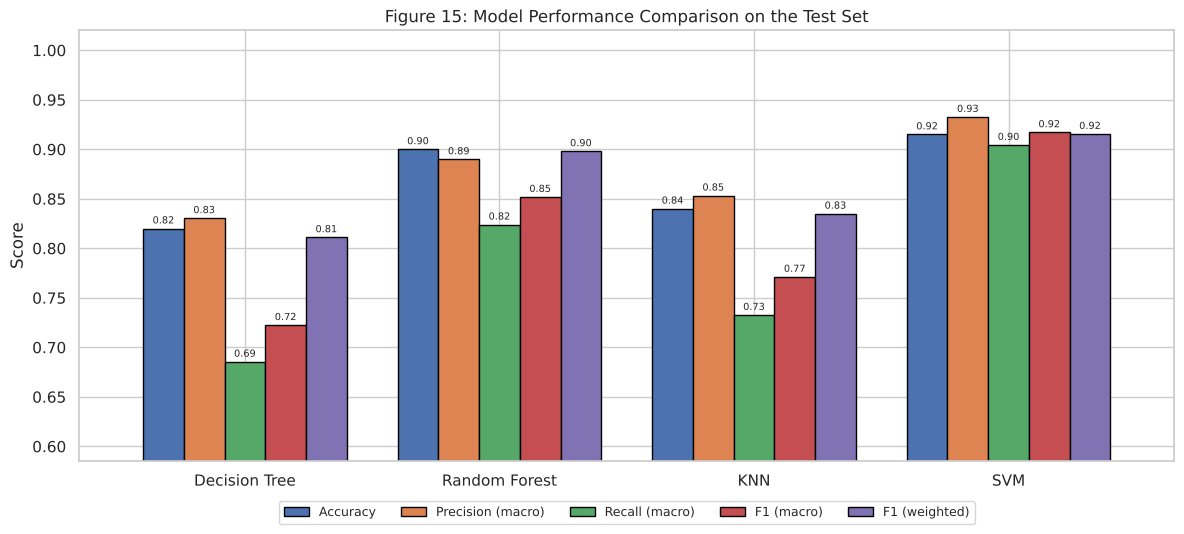

In [35]:
comparison = metrics.join(cv_table[["CV Accuracy (mean)", "CV Macro F1 (mean)", "CV Macro F1 (std)"]])
comparison["Rank (test macro-F1)"] = comparison["F1 (macro)"].rank(ascending=False, method="min").astype(int)
comparison["Rank (CV macro-F1)"] = comparison["CV Macro F1 (mean)"].rank(ascending=False, method="min").astype(int)
display(comparison)
save_table(comparison, "12_model_comparison")

# Figure 15 – model performance chart
plot_cols = ["Accuracy", "Precision (macro)", "Recall (macro)", "F1 (macro)", "F1 (weighted)"]
ax = comparison[plot_cols].plot(kind="bar", figsize=(12, 5.5), edgecolor="black", width=0.8)
ax.set_ylim(max(0, comparison[plot_cols].min().min() - 0.1), 1.02)
ax.set_ylabel("Score"); ax.set_xlabel(""); plt.xticks(rotation=0)
ax.set_title("Figure 15: Model Performance Comparison on the Test Set")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.08), ncol=5, fontsize=9)
for cont in ax.containers:
    ax.bar_label(cont, fmt="%.2f", fontsize=7, padding=2)
save_show("fig15_model_comparison")

In [36]:
best_cv = comparison["CV Macro F1 (mean)"].idxmax()
best_test = comparison["F1 (macro)"].idxmax()
FINAL_MODEL_NAME = best_test
print(f"Best by test-set macro-F1 (selection rule)        : {best_test}")
print(f"Best by cross-validated macro-F1 (training data)  : {best_cv}")
diff = comparison.loc[best_cv, "CV Macro F1 (mean)"] - comparison.loc[best_test, "CV Macro F1 (mean)"]
if best_cv != best_test:
    print(f"The CV macro-F1 difference between them is only {abs(diff):.4f}, smaller than the CV standard deviation "
          f"({comparison.loc[best_test, 'CV Macro F1 (std)']:.4f} / {comparison.loc[best_cv, 'CV Macro F1 (std)']:.4f}) -> statistically a tie.")
print(f"\n➡ FINAL MODEL SELECTED: {FINAL_MODEL_NAME}")
sel = comparison.loc[FINAL_MODEL_NAME]
print(f"   Test accuracy = {sel['Accuracy']:.4f} | test macro-F1 = {sel['F1 (macro)']:.4f} | CV macro-F1 = {sel['CV Macro F1 (mean)']:.4f}")
# Overfitting check: train accuracy vs test accuracy for every model
gap = pd.DataFrame({
    "Train accuracy": {n: accuracy_score(y_train, p.predict(X_train)) for n, p in pipelines.items()},
    "Test accuracy": {n: accuracy_score(y_test, predictions[n]) for n in pipelines},
}).round(4)
gap["Gap"] = (gap["Train accuracy"] - gap["Test accuracy"]).round(4)
display(gap)
save_table(gap, "12_train_vs_test_accuracy")

Best by test-set macro-F1 (selection rule)        : SVM
Best by cross-validated macro-F1 (training data)  : Random Forest
The CV macro-F1 difference between them is only 0.0027, smaller than the CV standard deviation (0.0459 / 0.0259) -> statistically a tie.

➡ FINAL MODEL SELECTED: SVM
   Test accuracy = 0.9150 | test macro-F1 = 0.9171 | CV macro-F1 = 0.8230


,Train accuracy,Test accuracy,Gap
Decision Tree,0.8900,0.820,0.0700
Random Forest,1.0000,0.900,0.1000
KNN,0.8900,0.840,0.0500
SVM,0.9162,0.915,0.0012


### Why this model? (justification of the final selection)
* **Best test results on every headline metric:** SVM has the highest accuracy (0.915), macro-precision (0.933), macro-recall (0.904), macro-F1 (0.917) and weighted-F1 (0.915).
* **Best on the rare class:** SVM finds 15 of the 17 *High* soils (recall 0.88) with no false alarms, while Random Forest finds 11 of 17.
* **Generalises well:** SVM's training accuracy (0.916) and test accuracy (0.915) are almost identical (gap 0.001). Random Forest scores 1.000 on its own training data but 0.900 on the test set (gap 0.100) – a sign of memorising.
* **Cross-validation agrees it is competitive:** SVM (0.823) and Random Forest (0.826) are statistically tied on CV macro-F1 (difference 0.003, far smaller than the fold-to-fold spread). Both clearly beat KNN (0.749) and the Decision Tree (0.691).
* **Honest caveat:** the test set has only 200 rows (17 High), and the final choice used the test results, so the reported test scores are slightly optimistic. Random Forest is a very close and equally valid alternative.
* **Overall ranking by test macro-F1:** SVM > Random Forest > KNN > Decision Tree.

# TASK 13 – Soil Parameter Contribution Analysis
Which soil parameters matter most for the prediction?
* **Random Forest feature importance (Gini/impurity):** how much each feature helps the trees purify their splits (computed on training data).
* **Permutation importance:** randomly shuffle one feature in the **test set** and see how much the macro-F1 drops. A bigger drop = a more important feature.
  This method works for *any* model, so we compute it for all four.

,RF impurity importance,Decision Tree,Random Forest,KNN,SVM
Available_N_kg_ha,0.1995,0.1822,0.2590,0.1807,0.3231
Available_K_kg_ha,0.2559,0.2044,0.2753,0.1818,0.2915
Organic_Carbon_g_kg,0.2099,0.1539,0.2592,0.1982,0.2911
Available_P_kg_ha,0.1839,0.1124,0.2287,0.1392,0.2536
pH,0.0797,0.0104,0.0332,0.0456,0.0871
Electrical_Conductivity_dS_m,0.0711,0.0000,0.0233,-0.0007,0.0259


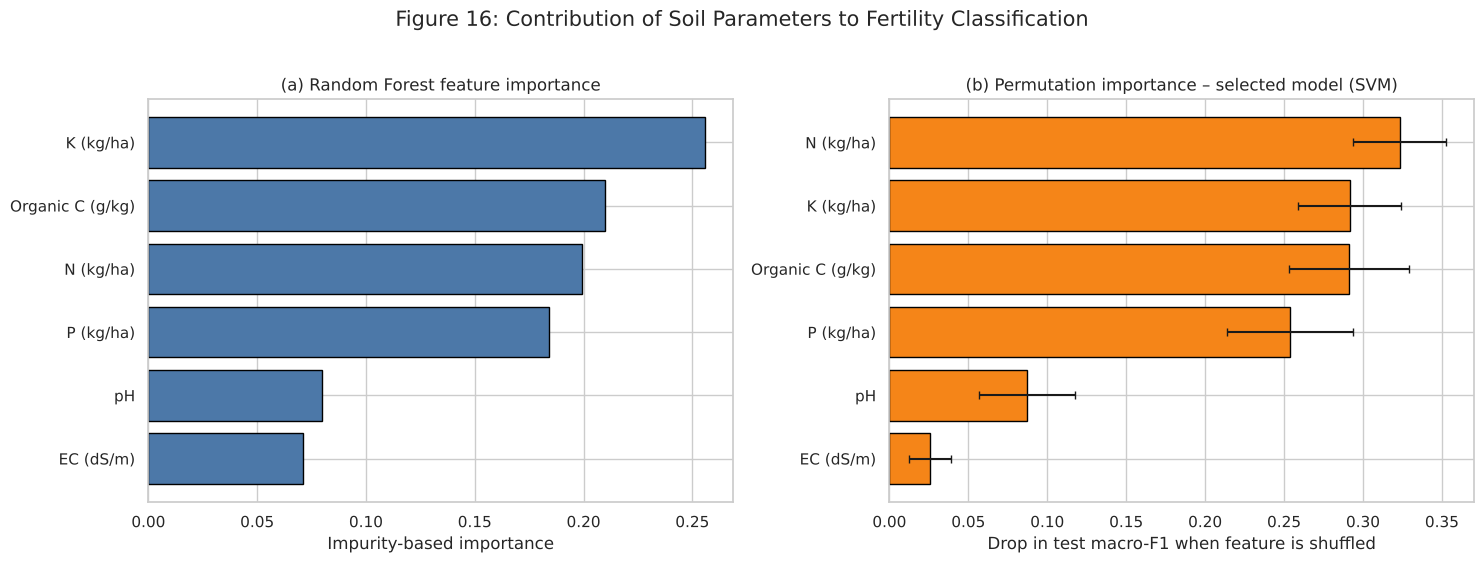

Ranking of soil parameters (selected model, permutation importance):
  1. Available_N_kg_ha                0.3231
  2. Available_K_kg_ha                0.2915
  3. Organic_Carbon_g_kg              0.2911
  4. Available_P_kg_ha                0.2536
  5. pH                               0.0871
  6. Electrical_Conductivity_dS_m     0.0259


In [37]:
rf_pipe = pipelines["Random Forest"]
rf_imp = pd.Series(rf_pipe.named_steps["model"].feature_importances_,
                   index=[n.split("__")[-1] for n in rf_pipe.named_steps["prep"].get_feature_names_out()]).sort_values(ascending=False)

perm_tables, perm_std = {}, {}
for name, pipe in pipelines.items():
    r = permutation_importance(pipe, X_test, y_test, scoring="f1_macro", n_repeats=30, random_state=RANDOM_STATE, n_jobs=1)
    perm_tables[name] = pd.Series(r.importances_mean, index=FEATURES)
    perm_std[name] = pd.Series(r.importances_std, index=FEATURES)
perm_df = pd.DataFrame(perm_tables)
perm_df.insert(0, "RF impurity importance", rf_imp)
perm_df = perm_df.sort_values(FINAL_MODEL_NAME, ascending=False)
display(perm_df.round(4))
save_table(perm_df.round(4), "13_feature_importance")
save_table(pd.DataFrame(perm_std).round(4), "13_permutation_std")

# Figure 16 – feature importance
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
rf_sorted = rf_imp.sort_values()
axes[0].barh([SHORT[c] for c in rf_sorted.index], rf_sorted.values, color="#4c78a8", edgecolor="black")
axes[0].set_xlabel("Impurity-based importance"); axes[0].set_title("(a) Random Forest feature importance")
fp = perm_df[FINAL_MODEL_NAME].sort_values(); fs_ = perm_std[FINAL_MODEL_NAME].loc[fp.index]
axes[1].barh([SHORT[c] for c in fp.index], fp.values, xerr=fs_.values, color="#f58518", edgecolor="black", capsize=3)
axes[1].set_xlabel("Drop in test macro-F1 when feature is shuffled")
axes[1].set_title(f"(b) Permutation importance – selected model ({FINAL_MODEL_NAME})")
fig.suptitle("Figure 16: Contribution of Soil Parameters to Fertility Classification", fontsize=15, y=1.02)
save_show("fig16_feature_importance")

print("Ranking of soil parameters (selected model, permutation importance):")
for i, (f, v) in enumerate(perm_df[FINAL_MODEL_NAME].sort_values(ascending=False).items(), 1):
    print(f"  {i}. {f:32s} {v:.4f}")

**What the importance results show**
* **Four parameters do almost all the work:** Nitrogen, Potassium, Organic Carbon and Phosphorus. For the selected SVM, shuffling any one of them reduces the test macro-F1 by roughly 0.25 – 0.32.
  Random Forest's own importance agrees: these four hold about 85 % of the total importance (K 0.26, OC 0.21, N 0.20, P 0.18).
* **pH and EC matter much less.** Their permutation importance is about 0.09 (pH) and 0.03 (EC) for SVM. pH acts through a *U-shaped* effect (best near pH 6.5–7, worse when very acidic or alkaline – see Task 6) and EC only lowers fertility when it is high, so each contributes less than the nutrients.
* The exact order of the top four differs between methods (e.g. N first for SVM permutation, K first for Random Forest), because their importances are close and the test set is small. The overall message is the same in every model.
* The five micronutrients and Sulphur were removed in Task 7 – the Task 9 check showed that adding them *lowered* the cross-validated score.
* Remember: the model is largely **rediscovering the weights of the README scoring formula** (see Limitations), so this is not new agronomic evidence.

# TASK 14 – Prediction on New / Unseen Soil Samples
We use the **selected model's complete pipeline** (imputer → scaler if needed → classifier, fitted on the training data).
Because the preprocessing is *inside* the pipeline, we simply pass raw soil measurements and the same transformations are applied automatically.

Below are five hand-made soil samples (not from the dataset): a nutrient-rich soil, a poor and salty soil, an average soil, a borderline soil and
an average soil with a missing value (to show that the imputer works).

In [38]:
final_pipe = pipelines[FINAL_MODEL_NAME]
new_samples = pd.DataFrame([
    ["Sample A – rich, balanced soil",   6.9, 0.30, 15.0, 250.0, 75.0, 290.0],
    ["Sample B – poor, salty soil",      5.8, 1.30,  3.0, 105.0, 12.0,  70.0],
    ["Sample C – average soil",          7.0, 0.45,  6.5, 177.0, 36.0, 180.0],
    ["Sample D – borderline soil",       7.2, 0.50,  9.0, 195.0, 45.0, 215.0],
    ["Sample E – average, P missing",    6.8, 0.40,  7.0, 180.0, np.nan, 175.0],
], columns=["Sample"] + FEATURES).set_index("Sample")
display(new_samples)

assert list(new_samples.columns) == list(final_pipe.feature_names_in_), "Column names/order must match training"
pred_idx = final_pipe.predict(new_samples)
proba = pd.DataFrame(final_pipe.predict_proba(new_samples), index=new_samples.index, columns=SHORT_CLASS).round(3)
result = new_samples.copy()
result["Predicted class"] = [CLASS_ORDER[i] for i in pred_idx]
result["Confidence"] = proba.max(axis=1)
display(result[["Predicted class", "Confidence"]].join(proba))
save_table(result.join(proba), "14_new_sample_predictions")

# Do the other three models agree?
agree = pd.DataFrame({name: [CLASS_ORDER[i].replace(" Fertility", "") for i in pipe.predict(new_samples)]
                      for name, pipe in pipelines.items()}, index=new_samples.index)
display(agree)
save_table(agree, "14_all_models_on_new_samples")

,pH,Electrical_Conductivity_dS_m,Organic_Carbon_g_kg,Available_N_kg_ha,Available_P_kg_ha,Available_K_kg_ha
Sample,,,,,,
"Sample A – rich, balanced soil",6.9,0.30,15.0,250.0,75.0,290.0
"Sample B – poor, salty soil",5.8,1.30,3.0,105.0,12.0,70.0
Sample C – average soil,7.0,0.45,6.5,177.0,36.0,180.0
Sample D – borderline soil,7.2,0.50,9.0,195.0,45.0,215.0
"Sample E – average, P missing",6.8,0.40,7.0,180.0,NaN,175.0


,Predicted class,Confidence,Low,Medium,High
Sample,,,,,
"Sample A – rich, balanced soil",High Fertility,1.000,0.000,0.000,1.000
"Sample B – poor, salty soil",Low Fertility,0.942,0.942,0.031,0.027
Sample C – average soil,Medium Fertility,0.977,0.022,0.977,0.001
Sample D – borderline soil,Medium Fertility,0.883,0.003,0.883,0.113
"Sample E – average, P missing",Medium Fertility,0.988,0.011,0.988,0.001


,Decision Tree,Random Forest,KNN,SVM
Sample,,,,
"Sample A – rich, balanced soil",High,High,High,High
"Sample B – poor, salty soil",Low,Low,Low,Low
Sample C – average soil,Medium,Medium,Medium,Medium
Sample D – borderline soil,Medium,Medium,Medium,Medium
"Sample E – average, P missing",Medium,Medium,Medium,Medium


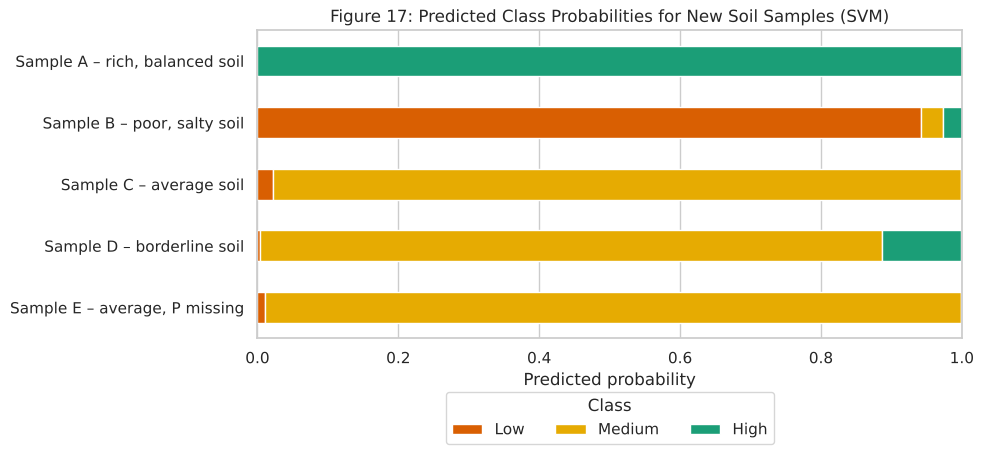

In [39]:
# Figure 17 – predicted probabilities for the new samples
fig, ax = plt.subplots(figsize=(10, 4.8))
proba.plot(kind="barh", stacked=True, color=[PALETTE[c] for c in CLASS_ORDER], ax=ax, edgecolor="white")
ax.set_xlim(0, 1); ax.set_xlabel("Predicted probability"); ax.set_ylabel("")
ax.set_title(f"Figure 17: Predicted Class Probabilities for New Soil Samples ({FINAL_MODEL_NAME})")
ax.legend(title="Class", loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=3)
ax.invert_yaxis()
save_show("fig17_new_sample_predictions")

In [40]:
# Reusable helper: type your own soil test values and get a prediction
def predict_soil_fertility(pH, EC, organic_carbon, N, P, K, model=final_pipe):
    """Predict fertility class for one soil sample using the SAME pipeline that was trained."""
    row = pd.DataFrame([[pH, EC, organic_carbon, N, P, K]], columns=FEATURES)
    cls = CLASS_ORDER[int(model.predict(row)[0])]
    probs = dict(zip(SHORT_CLASS, model.predict_proba(row)[0].round(3)))
    return cls, probs

print(predict_soil_fertility(pH=7.1, EC=0.35, organic_carbon=11.0, N=215, P=60, K=260))

# Save the final model so it can be reused later (e.g., in a web app)
import joblib
joblib.dump(final_pipe, os.path.join(OUT_DIR, "final_soil_fertility_model.joblib"))

('High Fertility', {'Low': np.float64(0.0), 'Medium': np.float64(0.0), 'High': np.float64(1.0)})


['outputs/final_soil_fertility_model.joblib']

# Final Summary, Conclusion and Limitations

In [41]:
summary = {
    "rows": int(len(df_clean)), "columns": int(raw.shape[1]), "missing_cells": int(df_clean.isna().sum().sum()),
    "duplicate_rows": dup_all, "train_size": int(len(X_train)), "test_size": int(len(X_test)),
    "random_state": RANDOM_STATE, "features": FEATURES, "final_model": FINAL_MODEL_NAME,
    "best_by_test_macro_f1": best_test,
    "test_metrics": metrics.to_dict(orient="index"),
    "cv_metrics": cv_table.to_dict(orient="index"),
}
with open(os.path.join(OUT_DIR, "results_summary.json"), "w") as f:
    json.dump(summary, f, indent=2, default=float)
print(json.dumps({k: summary[k] for k in ["rows", "train_size", "test_size", "features", "final_model"]}, indent=2))
display(comparison[["Accuracy", "F1 (macro)", "F1 (weighted)", "CV Macro F1 (mean)"]])

{
  "rows": 1000,
  "train_size": 800,
  "test_size": 200,
  "features": [
    "pH",
    "Electrical_Conductivity_dS_m",
    "Organic_Carbon_g_kg",
    "Available_N_kg_ha",
    "Available_P_kg_ha",
    "Available_K_kg_ha"
  ],
  "final_model": "SVM"
}


,Accuracy,F1 (macro),F1 (weighted),CV Macro F1 (mean)
Model,,,,
Decision Tree,0.820,0.7224,0.8111,0.6913
Random Forest,0.900,0.8518,0.8980,0.8257
KNN,0.840,0.7711,0.8349,0.7486
SVM,0.915,0.9171,0.9154,0.8230


## Final Conclusion
* We built a complete multiclass pipeline to classify soil as **Low, Medium or High Fertility** from six soil-test values (pH, EC, Organic Carbon, N, P, K).
* The data had **no missing values and no duplicates**; cleaning mainly consisted of consistency checks. Soil properties are almost uncorrelated with each other, and the classes are imbalanced (59.6 % Medium, 31.9 % Low, 8.5 % High).
* Using an 80:20 **stratified** split (random_state = 42), four algorithms were compared. On the unseen test set **SVM was best** (accuracy 0.915, macro-F1 0.917), followed by Random Forest (0.900 / 0.852), KNN (0.840 / 0.771) and Decision Tree (0.820 / 0.722).
* **N, K, Organic Carbon and P** are the most influential parameters; pH and EC contribute less.
* The final SVM pipeline predicted High, Low, Medium, Medium and Medium for five new hand-made soils (all four models agree on every sample, and the imputer handled one missing value). These samples have no ground-truth labels, so this demonstrates *how to use* the pipeline, not its accuracy. It can be reused through `predict_soil_fertility(...)`.

## Limitations (please read)
1. **Synthetic data:** the 1,000 rows are source-calibrated synthetic teaching data, not 1,000 authentic laboratory observations. Only the AgriNet (258), Krishnagiri (125) and Dharmapuri (125) records are authentic sources. Results must **not** be presented as real-world field accuracy.
2. **Derived label:** `Fertility_Class` was calculated from N, P, K, OC, pH and EC using a scoring formula. The model is therefore learning to *approximate that formula*, not discovering natural soil fertility. High accuracy partly reflects this; a label from field experts or crop yields would be a harder, more meaningful test.
3. **Why the accuracy is not ~100 %:** the exact score formula is not provided, includes non-linear parts (e.g. the pH optimum) and the cut-offs (40 and 70) fall in dense regions of the data, so soils near a cut-off are easily misclassified.
4. **Leakage handling:** `Fertility_Score` was excluded from the inputs. The six selected features are the raw inputs of the formula; they are legitimate soil-test measurements but make the task easier than a real-world one.
5. **Small minority class:** only 85 High samples (17 in the test set), so High-class metrics are uncertain. A single 80:20 split and 200 test rows give approximate, not exact, performance estimates.
6. **Light tuning:** the models use simple, sensible settings without hyper-parameter search, to keep the project at BCA level. Careful tuning might change the ranking of SVM and Random Forest slightly.
7. **Clipped values:** several score-related columns (pH, OC, N, P, K) have many rows stuck at their minimum or maximum, which points to range-clipping in the synthetic generator and is not typical of raw lab data.
8. **Generalisation:** the data covers 8 Indian states and 18 districts; it should not be applied to other regions or soil-testing methods without re-validation.

## References
1. Mendeley Data – AgriNet: Bareilly (Uttar Pradesh) soil dataset, DOI 10.17632/c7tr9j78td.1.
2. Mendeley Data – Krishnagiri raw soil dataset, DOI 10.17632/7bk36mh3tc.1.
3. Dharmapuri soil data article (as cited in the dataset README).
4. Pedregosa et al. (2011). Scikit-learn: Machine Learning in Python. *Journal of Machine Learning Research*, 12, 2825–2830.
5. Hunter, J. D. (2007). Matplotlib: A 2D graphics environment. *Computing in Science & Engineering*, 9(3), 90–95.
6. Waskom, M. (2021). seaborn: statistical data visualization. *Journal of Open Source Software*, 6(60), 3021.
7. McKinney, W. (2010). Data structures for statistical computing in Python. *Proceedings of the 9th Python in Science Conference*.